# 05: Gapless but quantized, or a Majorana thermal metal? Microscopic Kwant study of RHG V17

Companion to *Thermal Hall tomography of superconducting topology in rhombohedral graphene* (V17, arXiv:2608.12586).

**The open question.** V17 shows that warping and finite pair momentum keep the band invariant $C_{\rm band}=2$ while closing the zero-energy gap ($\delta_{\rm BdG}<0$ at 55% of the warped map), and gives the clean $T\to0$ value
$\kappa_{xy}/(Tq_M)=C_{\rm band}-\frac{1}{2\pi}\int_{|\xi_a|>\eta}\Omega$ (Eq. curvature-blocking). That is a ballistic statement. A pocketed chiral superconductor is a two-dimensional class-D metal, and class D is the 2D class in which weak disorder antilocalizes. The physical $T\to0$ response is therefore decided by localization, with three candidate fates:

| | regime | prediction | signature |
|---|---|---|---|
| **H1** | small pockets, $k_p\ell\lesssim1$ | pocket states localize; mobility gap restores $\kappa_{xy}/T=C_{\rm band}q_M$ although the DOS at $E=0$ is finite | **gapless but quantized** |
| **H2** | larger pockets | Majorana thermal metal: $\langle g\rangle$ grows with $\ln L$, $\kappa_{xy}$ unquantized | $\kappa_{xx}/T$ rises as $T\to0$ |
| **H3** | $L<\ell$ | V17 curvature-blocking value | non-universal, clean |

A second route to the metal is the domain network: each written wall carries $2|C|=4$ Majorana modes, and a percolating network of walls is itself a class-D metal (Zakharov, Fulga, Lemut, Tworzydlo, Beenakker, NJP 2025).

**What this notebook computes**

| Section | Microscopic result | Use in V18 |
|---|---|---|
| 1 | V17 model reproduced; lattice-resolved parameter set; pocket onset $w_c$ | Methods |
| 2 | Real-space Hamiltonian = Bloch model to $10^{-13}$; benchmarks $T_{\rm edge}=\lvert C\rvert$, $T_{\rm wall}=2\lvert C\rvert$, scattering Chern number | Methods / SI |
| 3 | Bridge: V17 kernel $\mathcal W_{\bf Q}$ = Fermi-sea Hall function convolution; real-space Kubo-Bastin (KPM) | validates Eqs. (kxy-exact-kernel)-(curvature-blocking) |
| 4 | Calibration on the canonical class-D thermal metal and insulator | benchmark |
| 5 | **Main scan**: disorder ensembles over warping $w$ and disorder $U$: $g(L)$, scattering Chern number $Q$, Bott index, DOS at $E=0$ | new central figure |
| 6 | Automatic classification and $(w,U)$ phase diagram | new central figure |
| 7 | Temperature dependence $K(T)/(q_MT)$ from energy-resolved transmission | experimental signature |
| 8 | Domain walls (sharp, suppressed, normal strip, contacts, current maps) and random writable textures | domain-wall prediction, network metal |
| 9 | Physical units and predictions | Discussion |
| 10 | Summary file to send back | |

**Conventions.** Nambu basis $(c,c^\dagger)$, spinless, intravalley. Transmission is the Nambu trace, so one perfectly transmitted chiral Majorana mode contributes 1 and $K/(q_MT)=\mathcal{T}(E\to0)$ with $q_M=\pi^2k_B^2/6h$. All energies and lengths are in model units (triangular lattice constant $a=1$) until Section 9.

**Installation** (conda-forge; MUMPS is essential for speed)
```bash
conda create -n kwant-env python=3.11
conda activate kwant-env
conda install -c conda-forge kwant python-mumps numpy scipy pandas matplotlib joblib jupyter
```
**Run modes** (set `RHG_RUN_MODE`, `RHG_N_JOBS`, `RHG_MEM_GB` in the environment or edit the configuration cell): `quick` (minutes, smoke test), `pilot` (first results, about 2 to 3 h on 20 workers), `production` (paper figures, about one day). Every task is checkpointed to disk and skipped on rerun.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS",
           "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"

import sys, time, json, hashlib, pickle, platform, warnings, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import ndimage
from scipy.optimize import brentq

warnings.filterwarnings("ignore", message=".*MUMPS.*")
import kwant
import kwant.solvers.default as _ksd
HAS_MUMPS = _ksd.smodule.__name__.endswith("mumps")

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm", "font.size": 11, "axes.labelsize": 12, "axes.titlesize": 11,
    "legend.fontsize": 8.5, "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True, "figure.dpi": 110, "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
print(f"python {platform.python_version()} | kwant {kwant.__version__} | numpy {np.__version__} | "
      f"MUMPS {'yes' if HAS_MUMPS else 'NO (SciPy fallback, much slower)'} | cores {os.cpu_count()}")

python 3.11.17 | kwant 1.5.0 | numpy 2.4.6 | MUMPS yes | cores 32


In [2]:
# =============================================================================
# Run configuration
# =============================================================================
RUN_MODE = os.environ.get("RHG_RUN_MODE", "pilot")
N_JOBS = int(os.environ.get("RHG_N_JOBS", 20))
MEM_GB = float(os.environ.get("RHG_MEM_GB", 80))      # memory budget for concurrent workers

# V17 warped finite-Q model, two parameter sets (same functional form, Appendix app:warped)
PAPER = dict(r_in=0.20, r_out=0.55, q=0.35, D0=2.0, chi=-1.0)    # V17 set (k-space continuity only)
LR = dict(r_in=0.45, r_out=1.35, q=0.90, D0=1.0, chi=-1.0)       # lattice-resolved set used for disorder
LR["Qx"] = 0.1 * LR["r_out"]                                      # V17 reference |Q| = 0.1 r_out
POINTS = {"G": 1.0, "P1": 2.2, "P2": 2.5, "P3": 3.0, "P4": 4.0}  # warping w: gapped, then growing pockets

CONFIGS = {
    "quick": dict(
        nk_C=121, nk_gap=241, nk_thermal=201, paper_map=(7, 6), w_scan=19,
        points=["G", "P1", "P2", "P3"], U=[0.0, 0.5, 1.5], L=[16, 24], seeds=3,
        L_wind=[24], seeds_wind=2, n_phi=12, L_bott=[12, 16], seeds_bott=2,
        L_dos=24, M_dos=800, nvec_dos=2,
        kpm_flake=24, M_kpm=800, kpm_tasks=2, nvec_kpm=2,
        calib_L=[16, 24, 32], calib_seeds=4,
        T_pairs=[("G", 0.5), ("P2", 1.5)], T_L=[24], T_seeds=2, nE=12,
        wall_Lx=[24, 40], wall_Wy=14, wall_seeds=2, wall_U=[0.0, 0.5],
        tex_L=[16, 24], tex_seeds=2, tex_frac=[0.5, 0.2], tex_ell=[3.0], tex_wind_L=16,
        map_Lx=32, map_Wy=14),
    "pilot": dict(
        nk_C=241, nk_gap=481, nk_thermal=401, paper_map=(25, 21), w_scan=46,
        points=["G", "P1", "P2", "P3", "P4"], U=[0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0],
        L=[24, 40, 64, 96, 128, 160], seeds=24,
        L_wind=[64, 128], seeds_wind=12, n_phi=24, L_bott=[24, 36, 48], seeds_bott=8,
        L_dos=96, M_dos=3000, nvec_dos=4,
        kpm_flake=60, M_kpm=2000, kpm_tasks=8, nvec_kpm=3,
        calib_L=[16, 24, 40, 64, 96, 128], calib_seeds=24,
        T_pairs=[("G", 0.5), ("P1", 0.5), ("P1", 1.5), ("P2", 1.0), ("P3", 1.0)],
        T_L=[64, 128], T_seeds=8, nE=28,
        wall_Lx=[32, 64, 128, 192], wall_Wy=37, wall_seeds=8, wall_U=[0.0, 0.5, 1.0],
        tex_L=[24, 40, 64, 96, 128], tex_seeds=16, tex_frac=[0.5, 0.25], tex_ell=[3.0, 6.0],
        tex_wind_L=64, map_Lx=64, map_Wy=24),
    "production": dict(
        nk_C=241, nk_gap=481, nk_thermal=601, paper_map=(25, 21), w_scan=91,
        points=["G", "P1", "P2", "P3", "P4"], U=[0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0],
        L=[32, 48, 72, 108, 160, 240, 320], seeds=48,
        L_wind=[96, 192], seeds_wind=24, n_phi=32, L_bott=[32, 48, 64], seeds_bott=16,
        L_dos=160, M_dos=6000, nvec_dos=6,
        kpm_flake=96, M_kpm=3000, kpm_tasks=16, nvec_kpm=3,
        calib_L=[16, 24, 40, 64, 96, 128, 192, 256], calib_seeds=48,
        T_pairs=[("G", 0.5), ("P1", 0.5), ("P1", 1.5), ("P2", 1.0), ("P3", 1.0), ("P4", 1.0)],
        T_L=[96, 192], T_seeds=16, nE=36,
        wall_Lx=[32, 64, 128, 192, 320], wall_Wy=46, wall_seeds=16, wall_U=[0.0, 0.5, 1.0, 1.5],
        tex_L=[24, 40, 64, 96, 128, 192, 240], tex_seeds=32, tex_frac=[0.5, 0.35, 0.25],
        tex_ell=[3.0, 6.0], tex_wind_L=96, map_Lx=96, map_Wy=32),
}
cfg = CONFIGS[RUN_MODE]
E0 = 1e-4          # transport energy (E -> 0, avoids exact band-edge degeneracies)
BUFFER = 2         # normal (Delta = 0) cells next to each lead
OUT = Path(f"out_05_rhg_{RUN_MODE}")
CACHE, FIG = OUT / "cache", OUT / "figures"
for _d in (OUT, CACHE, FIG):
    _d.mkdir(parents=True, exist_ok=True)
wy = lambda L: max(4, int(round(L / np.sqrt(3))))      # square samples: height sqrt3*Wy ~ L
print("RUN_MODE", RUN_MODE, "| workers", N_JOBS, "| memory budget", MEM_GB, "GB | output", OUT.resolve())

RUN_MODE pilot | workers 20 | memory budget 80.0 GB | output /home/kumar/Desktop/RHG_kwant/out_05_rhg_pilot


In [3]:
%%writefile rhg_kwant_core.py
# rhg_kwant_core.py
# Worker-side model, Kwant builders and observables for notebook 05 (RHG thermal-metal study).
# The notebook writes this file to disk so that joblib workers import identical code.
import json, functools, warnings
import numpy as np
import kwant

warnings.filterwarnings("ignore", message=".*MUMPS.*")

SQ3 = np.sqrt(3.0)
TZ = np.diag([1.0, -1.0]).astype(complex)
SX = np.array([[0, 1], [1, 0]], complex)
SY = np.array([[0, -1j], [1j, 0]], complex)

# =============================================================================
# 1. k-space model: identical functional form to RHG_warped_finiteQ.ipynb (V17)
# =============================================================================
B = np.array([[1.0, 0.0], [-0.5, SQ3 / 2], [-0.5, -SQ3 / 2]])
A1 = np.array([1.0, 0.0])
A2 = np.array([0.5, SQ3 / 2])
GM = 2 * np.pi * np.linalg.inv(np.array([A1, A2])).T          # rows: G1, G2
AREA_PER_SITE = SQ3 / 2


def _dots(kx, ky):
    return [kx * b[0] + ky * b[1] for b in B]


def rho2(kx, ky):
    return (4.0 / 3.0) * (3.0 - sum(np.cos(x) for x in _dots(kx, ky)))


def g3(kx, ky):
    return sum(np.sin(x) for x in _dots(kx, ky))


def sxy(kx, ky):
    d = _dots(kx, ky)
    return ((2.0 / 3.0) * sum(B[i, 0] * np.sin(d[i]) for i in range(3)),
            (2.0 / 3.0) * sum(B[i, 1] * np.sin(d[i]) for i in range(3)))


def xi_normal(kx, ky, p):
    r2 = rho2(kx, ky)
    return (r2 - p["r_in"] ** 2) * (r2 - p["r_out"] ** 2) + p["w"] * g3(kx, ky)


def gap_k(kx, ky, p):
    sx, sy = sxy(kx, ky)
    c, q = p["chi"], p["q"]
    return p["D0"] * (sx + 1j * c * sy) * (sx - q + 1j * c * sy) * (sx + q + 1j * c * sy)


def bdg_fields(kx, ky, p):
    """(xi_s, xi_a, Delta) for pair momentum (Qx, Qy), following Yang and Zhang."""
    Qx, Qy = p.get("Qx", 0.0), p.get("Qy", 0.0)
    xp = xi_normal(kx + Qx / 2, ky + Qy / 2, p)
    xm = xi_normal(-kx + Qx / 2, -ky + Qy / 2, p)
    return 0.5 * (xp + xm), 0.5 * (xp - xm), gap_k(kx, ky, p)


def bloch_bdg(kx, ky, p):
    """[[xi(k+Q/2), Delta(k)], [Delta*(k), -xi(-k+Q/2)]] with shape (..., 2, 2)."""
    Qx, Qy = p.get("Qx", 0.0), p.get("Qy", 0.0)
    xp = xi_normal(kx + Qx / 2, ky + Qy / 2, p)
    xm = xi_normal(-kx + Qx / 2, -ky + Qy / 2, p)
    D = gap_k(kx, ky, p)
    H = np.zeros(np.shape(kx) + (2, 2), complex)
    H[..., 0, 0] = xp; H[..., 1, 1] = -xm; H[..., 0, 1] = D; H[..., 1, 0] = np.conj(D)
    return H


def bz_grid(Nk):
    f = np.arange(Nk) / Nk
    F1, F2 = np.meshgrid(f, f, indexing="ij")
    return F1 * GM[0, 0] + F2 * GM[1, 0], F1 * GM[0, 1] + F2 * GM[1, 1]


def fhs_chern(xi_s, D):
    """FHS Chern number of the lower band of d=(Re D, -Im D, xi_s) (same code as V17) and the
    plaquette fluxes F[i, j] of the plaquette with lower-left corner (i, j)."""
    dx, dy, dz = np.real(D), -np.imag(D), xi_s
    n = np.sqrt(dx ** 2 + dy ** 2 + dz ** 2)
    uA = np.stack([dz - n, dx + 1j * dy], -1)
    uB = np.stack([-(dx - 1j * dy), dz + n], -1)
    u = np.where((dz <= 0)[..., None], uA, uB)
    nrm = np.linalg.norm(u, axis=-1, keepdims=True)
    u = u / np.where(nrm == 0, 1.0, nrm)

    def lk(a, b):
        s = np.sum(np.conj(a) * b, -1)
        return s / np.where(np.abs(s) == 0, 1.0, np.abs(s))
    U1 = lk(u, np.roll(u, -1, 0)); U2 = lk(u, np.roll(u, -1, 1))
    F = np.angle(U1 * np.roll(U2, -1, 0) / np.roll(U1, -1, 1) / U2)
    return F.sum() / (2 * np.pi), F


def kspace_summary(p, Nk_C=241, Nk_gap=481):
    kx, ky = bz_grid(Nk_C)
    xs, xa, D = bdg_fields(kx, ky, p)
    C, F = fhs_chern(xs, D)
    kx, ky = bz_grid(Nk_gap)
    xs, xa, D = bdg_fields(kx, ky, p)
    eta = np.sqrt(xs ** 2 + np.abs(D) ** 2)
    dl = eta - np.abs(xa)
    return dict(C=float(C), maxF=float(np.abs(F).max()), delta_BdG=float(dl.min()),
                eta_min=float(eta.min()), pocket_area_frac=float((dl < 0).mean()))


# ---- exact thermal kernel of V17, Eq. (kernel-G), extended as an odd function
def _li2_neg_exp(a):
    z = -np.exp(-2 * a)
    k = np.arange(1, 300)
    return np.sum(z[..., None] ** k / k ** 2, axis=-1)


def G_kernel(x):
    x = np.asarray(x, float)
    a = np.minimum(np.abs(x), 40.0)
    out = 1 - (12 / np.pi ** 2) * (a ** 2 * (1 - np.tanh(a)) + 2 * a * np.log1p(np.exp(-2 * a))
                                    - _li2_neg_exp(a))
    out = np.where(np.abs(x) >= 40.0, 1.0, out)
    return np.sign(x) * out


def kspace_thermal(p, Nk=401, thetas=(), E_grid=None):
    """Clean two-band thermal Hall of V17 on a plaquette grid.
    Returns C_band, curvature-blocking T->0 value, A_Omega, kappa/(T q_M) via the branch weight W_Q
    (V17 Eq. branch-weight), the Fermi-sea Hall function s(E), and kappa via the s(E) convolution."""
    kx, ky = bz_grid(Nk)
    xs, xa, D = bdg_fields(kx, ky, p)
    C, F = fhs_chern(xs, D)
    eta = np.sqrt(xs ** 2 + np.abs(D) ** 2)
    av = lambda a: 0.25 * (a + np.roll(a, -1, 0) + np.roll(a, -1, 1) + np.roll(np.roll(a, -1, 0), -1, 1))
    eta_p, xa_p = av(eta), av(xa)
    Em, Ep = xa_p - eta_p, xa_p + eta_p
    blocked = np.abs(xa_p) > eta_p
    res = dict(C_band=float(C), A_Omega=float(np.abs(F).sum() / (2 * np.pi)),
               blocking_T0=float(F[~blocked].sum() / (2 * np.pi)),
               pocket_curvature=float(F[blocked].sum() / (2 * np.pi)),
               delta_BdG=float((eta - np.abs(xa)).min()))
    kap = []
    for th in thetas:
        W = 0.5 * (G_kernel((eta_p + xa_p) / (2 * th)) + G_kernel((eta_p - xa_p) / (2 * th)))
        kap.append(float((F * W).sum() / (2 * np.pi)))
    res["kappa_WQ"] = np.array(kap)
    if E_grid is not None:
        Ff, Emf, Epf = F.ravel(), Em.ravel(), Ep.ravel()
        om = np.argsort(Emf); op = np.argsort(Epf)
        cm = np.concatenate([[0], np.cumsum(Ff[om])]); cp = np.concatenate([[0], np.cumsum(Ff[op])])
        im = np.searchsorted(Emf[om], E_grid); ip = np.searchsorted(Epf[op], E_grid)
        s = (cm[im] - cp[ip]) / (2 * np.pi)       # lower band filled minus upper band (Omega_+ = -Omega_-)
        res["s_E"] = s
        kconv = []
        for th in thetas:
            x = np.clip(E_grid / (2 * th), -300, 300)
            mdf = 1.0 / (4 * th * np.cosh(x) ** 2)
            kconv.append(float(3 / (np.pi ** 2 * th ** 2) * np.trapezoid(E_grid ** 2 * mdf * s, E_grid)))
        res["kappa_conv"] = np.array(kconv)
    return res


def normal_dos_at_EF(p, Nk=601, width=0.01):
    """Normal-state DOS per site per unit energy at E=0 (Lorentzian-free histogram estimate)."""
    kx, ky = bz_grid(Nk)
    xi = xi_normal(kx, ky, p)
    return float((np.abs(xi) < width).mean() / (2 * width))


# =============================================================================
# 2. Real-space hoppings by exact Fourier inversion of the Bloch functions
#    convention f(k) = sum_d f_d exp(-i k.d),  d = n1 A1 + n2 A2
# =============================================================================
def fourier_coeffs(func, R=4, N=24, tol=1e-12):
    kx, ky = bz_grid(N)
    vals = func(kx, ky)
    out = {}
    for n1 in range(-R, R + 1):
        for n2 in range(-R, R + 1):
            d = n1 * A1 + n2 * A2
            c = np.mean(vals * np.exp(1j * (kx * d[0] + ky * d[1])))
            if abs(c) > tol:
                out[(n1, n2)] = complex(c)
    return out


def model_key(p):
    return json.dumps({k: float(p[k]) for k in ("r_in", "r_out", "w", "q", "D0", "chi")}, sort_keys=True)


@functools.lru_cache(maxsize=64)
def model_hoppings(key):
    p = json.loads(key)
    return (fourier_coeffs(lambda kx, ky: xi_normal(kx, ky, p)),
            fourier_coeffs(lambda kx, ky: gap_k(kx, ky, p)))


def reconstruct_error(p, n_test=200, seed=0):
    t, dl = model_hoppings(model_key(p))
    rng = np.random.default_rng(seed)
    err = 0.0
    for _ in range(n_test):
        kx, ky = rng.uniform(-np.pi, np.pi, 2)
        ph = lambda n1, n2: np.exp(-1j * (kx * (n1 + n2 / 2) + ky * n2 * SQ3 / 2))
        e = sum(c * ph(*d) for d, c in t.items())
        dd = sum(c * ph(*d) for d, c in dl.items())
        err = max(err, abs(e - xi_normal(kx, ky, p)), abs(dd - gap_k(kx, ky, p)))
    rng_of = lambda dct: max(max(abs(a), abs(b), abs(a + b)) for (a, b) in dct)
    odd = max(abs(dl[k] + dl.get((-k[0], -k[1]), 0)) for k in dl)
    return dict(max_err=float(err), normal_range=rng_of(t), pairing_range=rng_of(dl),
                n_normal=len(t), n_pairing=len(dl), pairing_oddness=float(odd))


# =============================================================================
# 3. Lattice geometry. Integer coordinates (X, j): x = X/2, y = j*sqrt(3)/2, X = j (mod 2).
#    Kwant: rectangular cell (1, sqrt3) with two sublattices.
# =============================================================================
LAT = kwant.lattice.general([(1, 0), (0, SQ3)], [(0, 0), (0.5, SQ3 / 2)], norbs=2, name=["a", "b"])
SUBL = LAT.sublattices


def site_of(X, j):
    s = j % 2
    return SUBL[s]((X - s) // 2, j // 2)


def xj_of(site):
    s = 0 if site.family is SUBL[0] else 1
    ix, iy = site.tag
    return 2 * ix + s, 2 * iy + s


def nambu_block(t, d):
    """Kwant block H[target, source] for electron hopping t and odd pairing amplitude d."""
    return np.array([[t, d], [-np.conj(d), -np.conj(t)]], dtype=complex)


def _half(n1, n2):
    return n2 > 0 or (n2 == 0 and n1 > 0)


@functools.lru_cache(maxsize=8)
def _noise(seed, nX, nJ):
    return np.random.default_rng(seed).uniform(-1.0, 1.0, size=(nX, nJ))


@functools.lru_cache(maxsize=32)
def domain_mask(seed, nX, nJ, ell, frac, periodic_j=True):
    """True = domain B (time-reversed partner). Smoothed Gaussian random field with correlation
    length `ell` (lattice units), thresholded so that a fraction `frac` of the grid is B."""
    from scipy import ndimage
    f = np.random.default_rng(10_000 + seed).normal(size=(nX, nJ))
    f = ndimage.gaussian_filter(f, sigma=(2 * ell, 2 * ell / SQ3),
                                mode=("nearest", "wrap" if periodic_j else "nearest"))
    return f > np.quantile(f, 1 - frac)


def _twist(M, sign):
    """Seam hopping with a twisted boundary condition psi -> exp(i phi) psi applied to the full Nambu
    spinor. This is a fictitious U(1) twist (not a charge flux): it treats H_BdG as a class-A matrix, whose
    Chern number is the class-D invariant C_BdG, as in the Bott index."""
    def val(s1, s2, phi):
        return np.exp(-1j * sign * phi) * M
    return val


def build_system(g):
    """g: geometry + model dict.
       kind: 'torus' (periodic x,y; gauge frame) | 'cylinder' (periodic y, leads along x) |
             'strip' (open y, leads along x) | 'flake' (open, no leads)
       Lx, Wy: cells (width Lx, height sqrt3*Wy, 2*Lx*Wy sites); frame: 'gauge' | 'lab'
       model: r_in r_out w q D0 chi Qx ; buffer: normal (Delta=0) cells next to each lead
       texture: None | 'wall2' (two walls, cylinder) | 'wall1' (one wall, strip) | 'random'
       wall_kind: 'sharp' | 'suppressed' | 'normal'; wall_width (lattice units); wall_lambda
       ell_d, frac_d, tex_seed for random textures.
    Kwant params at solve time: U (uniform on-site disorder amplitude), seed, mu_shift, phi (flux twist)."""
    Lx, Wy = int(g["Lx"]), int(g["Wy"])
    nX, nJ = 2 * Lx, 2 * Wy
    kind = g["kind"]
    per_x = kind == "torus"
    per_j = kind in ("torus", "cylinder")
    gauge = g.get("frame", "lab") == "gauge"
    Qx = float(g.get("Qx", 0.0))
    t, dl = model_hoppings(model_key(g))
    buf = int(g.get("buffer", 0)) if kind in ("cylinder", "strip") else 0
    x_sc0, x_sc1 = buf, Lx - buf
    in_sc = lambda X: x_sc0 <= X / 2 < x_sc1

    tex = g.get("texture")
    H_y = nJ * SQ3 / 2
    if tex == "wall2":
        walls = [H_y / 4, 3 * H_y / 4]
        maskB = np.broadcast_to(((np.arange(nJ) * SQ3 / 2 >= walls[0]) & (np.arange(nJ) * SQ3 / 2 < walls[1]))[None, :], (nX, nJ))
    elif tex == "wall1":
        walls = [H_y / 2]
        maskB = np.broadcast_to((np.arange(nJ) * SQ3 / 2 < walls[0])[None, :], (nX, nJ))
    elif tex == "random":
        walls = []
        maskB = domain_mask(int(g["tex_seed"]), nX, nJ, float(g["ell_d"]), float(g["frac_d"]), per_j)
    else:
        walls, maskB = [], None
    wk, ww, wl = g.get("wall_kind", "sharp"), float(g.get("wall_width", 0.0)), float(g.get("wall_lambda", 1.0))

    def wall_dist(X, j):
        if not walls:
            return np.inf
        y = j * SQ3 / 2
        if per_j:
            return min(min(abs(y - w), H_y - abs(y - w)) for w in walls)
        return min(abs(y - w) for w in walls)

    def pair_scale(X, j):
        if wk in ("suppressed", "normal") and ww > 0 and wall_dist(X, j) < ww / 2:
            return 0.0 if wk == "normal" else wl
        return 1.0

    def inB(X, j):
        return maskB is not None and in_sc(X) and bool(maskB[X % nX, j % nJ])

    sites = {}
    for j in range(nJ):
        s = j % 2
        for ix in range(Lx):
            sites[(2 * ix + s, j)] = site_of(2 * ix + s, j)

    syst = kwant.Builder()
    t0 = t.get((0, 0), 0.0).real

    def onsite(site, U, seed, mu_shift):
        X, j = xj_of(site)
        v = 0.0 if U == 0 else U * _noise(int(seed), nX, nJ)[X % nX, j % nJ]
        return (t0 - mu_shift + v) * TZ

    for st in sites.values():
        syst[st] = onsite

    for (n1, n2) in set(list(t) + list(dl)):
        if not _half(n1, n2):
            continue
        dX, dj = 2 * n1 + n2, n2
        dxc = n1 + n2 / 2
        tc, dc = t.get((n1, n2), 0.0), dl.get((n1, n2), 0.0)
        te0 = tc * (np.exp(-1j * Qx * dxc / 2) if gauge else 1.0)
        for (X, j), st in sites.items():
            X2, j2 = X + dX, j + dj
            crossed = 0
            if per_x:
                X2 %= nX
            if per_j and j2 >= nJ:
                j2 -= nJ; crossed = 1
            tgt = sites.get((X2, j2))
            if tgt is None:
                continue
            te = te0
            de = 0.0
            if dc != 0 and (buf == 0 or (in_sc(X) and in_sc(X + dX))):
                sc = 0.5 * (pair_scale(X, j) + pair_scale(X + dX, j + dj))
                de = dc * sc * (1.0 if gauge else np.exp(1j * Qx * (X / 2 + dxc / 2)))
            if maskB is not None:
                bA, bB = inB(X, j), inB(X + dX, j + dj)
                if bA and bB:
                    te, de = np.conj(te), np.conj(de)
                elif bA != bB:
                    te, de = np.real(te), np.real(de)
            if te == 0 and de == 0:
                continue
            M = nambu_block(te, de)
            syst[tgt, st] = _twist(M, +1) if (crossed and kind == "cylinder") else M

    if kind in ("cylinder", "strip"):
        P = 2
        lead_type = g.get("lead_type", "chains")
        tL = float(g.get("t_lead", 1.0))
        for direction in (-1, +1):
            lead = kwant.Builder(kwant.TranslationalSymmetry((direction * P, 0)))
            lsites = {}
            for j in range(nJ):
                s = j % 2
                for ix in range(P):
                    lsites[(2 * ix + s, j)] = site_of(2 * ix + s, j)
            if lead_type == "chains":
                # decoupled 1D chains along x (one per row): mode content independent of the twist phi,
                # as required by the scattering formula for the Chern number (Fulga et al. 2012)
                for st in lsites.values():
                    lead[st] = 0.0 * TZ
                for (X, j), st in lsites.items():
                    lead[site_of(X + 2, j), st] = nambu_block(-tL, 0.0)
            else:
                # normal metal with the same xi(k) and Delta = 0
                for st in lsites.values():
                    lead[st] = t0 * TZ
                for (n1, n2), tc in t.items():
                    if not _half(n1, n2):
                        continue
                    dX, dj = 2 * n1 + n2, n2
                    for (X, j), st in lsites.items():
                        j2, crossed = j + dj, 0
                        if per_j and j2 >= nJ:
                            j2 -= nJ; crossed = 1
                        elif not (0 <= j2 < nJ):
                            continue
                        M = nambu_block(tc, 0.0)
                        lead[site_of(X + dX, j2), st] = _twist(M, +1) if crossed else M
            syst.attach_lead(lead)
    return syst.finalized()


# ---- calibration model: square-lattice spinless p+ip (V17 Methods anchor), random chemical potential
def build_pip(g):
    """Square lattice, d = (D sin kx, D sin ky, 2t(2 - cos kx - cos ky) - mu). C = +1 (0 < mu < 4t) and
    -1 (4t < mu < 8t) in the V17 FHS convention. Cylinder periodic in y, normal leads (Delta = 0, mu_lead)."""
    L, W = int(g["Lx"]), int(g["Wy"])
    t, D, mu_bar, mu_lead = g.get("t", 1.0), g["D"], g["mu_bar"], g.get("mu_lead", g["mu_bar"])
    lat = kwant.lattice.square(norbs=2)
    syst = kwant.Builder()

    def onsite(site, U, seed, mu_shift):
        x, y = site.tag
        v = 0.0 if U == 0 else U * _noise(int(seed), L, W)[x, y]
        return (4 * t - mu_bar - v - mu_shift) * TZ
    for x in range(L):
        for y in range(W):
            syst[lat(x, y)] = onsite
    hx = -t * TZ + 0.5j * D * SX
    hy = -t * TZ + 0.5j * D * SY
    for x in range(L):
        for y in range(W):
            if x + 1 < L:
                syst[lat(x + 1, y), lat(x, y)] = hx
            if y + 1 < W:
                syst[lat(x, y + 1), lat(x, y)] = hy
            else:
                syst[lat(x, 0), lat(x, y)] = _twist(hy, +1)
    for direction in (-1, +1):
        # decoupled 1D chains (see build_system)
        lead = kwant.Builder(kwant.TranslationalSymmetry((direction, 0)))
        for y in range(W):
            lead[lat(0, y)] = 0.0 * TZ
        for y in range(W):
            lead[lat(1, y), lat(0, y)] = -t * TZ
        syst.attach_lead(lead)
    return syst.finalized()


# =============================================================================
# 4. Observables (worker tasks)
# =============================================================================
def gkey(g):
    return json.dumps(g, sort_keys=True)


def build_pip_flake(g):
    """Open square flake of the p+ip anchor (no leads), for the KPM Hall calibration."""
    L, t, D, mu = int(g["Lx"]), g.get("t", 1.0), g["D"], g["mu_bar"]
    lat = kwant.lattice.square(norbs=2)
    syst = kwant.Builder()

    def onsite(site, U, seed, mu_shift):
        x, y = site.tag
        v = 0.0 if U == 0 else U * _noise(int(seed), L, L)[x, y]
        return (4 * t - mu - v - mu_shift) * TZ
    for x in range(L):
        for y in range(L):
            syst[lat(x, y)] = onsite
    syst[kwant.builder.HoppingKind((1, 0), lat)] = -t * TZ + 0.5j * D * SX
    syst[kwant.builder.HoppingKind((0, 1), lat)] = -t * TZ + 0.5j * D * SY
    return syst.finalized()


@functools.lru_cache(maxsize=2)
def cached_system(key):
    g = json.loads(key)
    if g["kind"] == "pip_cylinder":
        return build_pip(g)
    if g["kind"] == "pip_flake":
        return build_pip_flake(g)
    return build_system(g)


def _params(U, seed, phi=0.0, mu_shift=0.0):
    return dict(U=float(U), seed=int(seed), mu_shift=float(mu_shift), phi=float(phi))


def det_r_winding(fsyst, E, U, seed, phis):
    """Scattering Chern number (Fulga, Hassler, Akhmerov, PRB 85, 165409 (2012)): winding of det r(phi)
    of the left-lead reflection matrix as the flux phi threading the cylinder runs over 2 pi."""
    dets = []
    for ph in phis:
        S = kwant.smatrix(fsyst, E, params=_params(U, seed, ph))
        r = S.submatrix(0, 0)
        sgn, logabs = np.linalg.slogdet(r)
        dets.append(sgn * np.exp(logabs))
    dets = np.array(dets)
    ang = np.unwrap(np.angle(np.append(dets, dets[0])))
    return float((ang[-1] - ang[0]) / (2 * np.pi)), float(np.abs(dets).min())


def task_transport(key, seeds, U, E_list, phis=None, E_wind=1e-4):
    """Two-terminal transmission T_{R<-L}(E) (Nambu trace = Majorana units) for each seed, and,
    if `phis` is given, the scattering winding number at E_wind."""
    fsyst = cached_system(key)
    out = []
    for sd in seeds:
        rec = dict(seed=int(sd), U=float(U))
        T = []
        for E in E_list:
            try:
                S = kwant.smatrix(fsyst, float(E), params=_params(U, sd))
                T.append(S.transmission(1, 0))
            except Exception:
                T.append(np.nan)
        rec["T"] = np.array(T)
        if phis is not None:
            try:
                rec["Q"], rec["min_abs_det_r"] = det_r_winding(fsyst, E_wind, U, sd, phis)
            except Exception:
                rec["Q"], rec["min_abs_det_r"] = np.nan, np.nan
        out.append(rec)
    return out


def task_winding(key, seeds, U, phis, E=1e-4):
    """Scattering Chern number Q and min_phi |det r| for each seed (system must have chain leads)."""
    fsyst = cached_system(key)
    out = []
    for sd in seeds:
        try:
            Q, md = det_r_winding(fsyst, E, U, sd, phis)
        except Exception:
            Q, md = np.nan, np.nan
        out.append(dict(seed=int(sd), U=float(U), Q=Q, min_abs_det_r=md))
    return out


def task_bott(key, seeds, U):
    """Bott index of all negative-energy BdG states on a torus, plus low-energy level counts."""
    fsyst = cached_system(key)
    g = json.loads(key)
    pos = np.array([s.pos for s in fsyst.sites])
    ux = np.repeat(np.exp(2j * np.pi * pos[:, 0] / g["Lx"]), 2)
    uy = np.repeat(np.exp(2j * np.pi * pos[:, 1] / (SQ3 * g["Wy"])), 2)
    out = []
    for sd in seeds:
        H = fsyst.hamiltonian_submatrix(params=_params(U, sd))
        w, v = np.linalg.eigh(H)
        occ = v[:, w < 0]
        Ux = occ.conj().T @ (ux[:, None] * occ)
        Uy = occ.conj().T @ (uy[:, None] * occ)
        ev = np.linalg.eigvals(Uy @ Ux @ Uy.conj().T @ Ux.conj().T)
        absw = np.abs(w)
        out.append(dict(seed=int(sd), U=float(U), bott=float(np.sum(np.angle(ev)) / (2 * np.pi)),
                        min_abs_E=float(absw.min()), n_sites=len(fsyst.sites),
                        n_lt=[int((absw < e).sum()) for e in (0.005, 0.01, 0.02, 0.04)]))
    return out


def task_kpm_dos(key, seed, U, energies, num_moments, num_vectors=4):
    """KPM density of states per site per unit energy (Nambu: counts both particle and hole)."""
    fsyst = cached_system(key)
    sd = kwant.kpm.SpectralDensity(fsyst, params=_params(U, seed), num_moments=int(num_moments),
                                   num_vectors=int(num_vectors), rng=int(seed))
    return np.real(sd(np.asarray(energies))) / len(fsyst.sites)


def task_kpm_sxy(key, U, seed, energies, num_moments, num_vectors, temperature, frac=0.5):
    """Real-space Kubo-Bastin Hall function s(E) of the BdG Hamiltonian on an open flake, sampled in
    the central region (fraction `frac` of each side). Raw Kwant output divided by the sampled area.
    The sign/normalization is calibrated in the notebook on the p+ip anchor."""
    fsyst = cached_system(key)
    g = json.loads(key)
    pip = g["kind"] == "pip_flake"
    Lx, Hy = (g["Lx"], g["Lx"]) if pip else (g["Lx"], SQ3 * g["Wy"])
    aps = 1.0 if pip else AREA_PER_SITE
    lo, hi = (1 - frac) / 2, (1 + frac) / 2
    where = lambda s: (lo * Lx <= s.pos[0] < hi * Lx) and (lo * Hy <= s.pos[1] < hi * Hy)
    n_where = sum(1 for s in fsyst.sites if where(s))
    vf = kwant.kpm.RandomVectors(fsyst, where=where, rng=int(seed))
    cond = kwant.kpm.conductivity(fsyst, alpha="x", beta="y", params=_params(U, seed),
                                  num_moments=int(num_moments), num_vectors=int(num_vectors),
                                  vector_factory=vf, rng=int(seed))
    vals = np.array([cond(mu=float(e), temperature=float(temperature)) for e in energies])
    return np.real(vals) / (n_where * aps)


def current_map(key, E, U=0.0, seed=0, lead=0):
    """Quasiparticle probability current of all scattering states injected from `lead` at energy E.
    Returns hopping midpoints, direction vectors and current values."""
    fsyst = cached_system(key)
    wf = kwant.wave_function(fsyst, energy=E, params=_params(U, seed))
    psi = wf(lead)
    J = kwant.operator.Current(fsyst)
    cur = sum(J(p, params=_params(U, seed)) for p in psi)
    pos = np.array([s.pos for s in fsyst.sites])
    hops = np.array(fsyst.graph.tail_head_pairs) if hasattr(fsyst.graph, "tail_head_pairs") else \
        np.array([(fsyst.graph.tail(i), fsyst.graph.head(i)) for i in range(fsyst.graph.num_edges)])
    return pos, hops, np.asarray(cur)


def thermal_from_T(E, T, theta):
    """K/(q_M T) = (6/(pi^2 theta^2)) int_0^inf dE E^2 (-df/dE) T(E), Nambu-trace transmission T(E)=T(-E)."""
    x = np.clip(E / (2 * theta), -300, 300)
    mdf = 1.0 / (4 * theta * np.cosh(x) ** 2)
    return float(6 / (np.pi ** 2 * theta ** 2) * np.trapezoid(E ** 2 * mdf * T, E))


def cut_current_profile(key, E, U=0.0, seed=0, lead=0):
    """Quasiparticle probability current through the vertical cut x = Lx/2 for all scattering states
    injected from `lead` at energy E. Returns (y_mid, I) per crossing hopping; sum(I) = T_{other<-lead}."""
    fsyst = cached_system(key)
    prm = _params(U, seed)
    psi = kwant.wave_function(fsyst, energy=E, params=prm)(lead)
    g = json.loads(key)
    xc = g["Lx"] / 2 - 0.25
    pos = np.array([s.pos for s in fsyst.sites])
    out = []
    for i in range(len(fsyst.sites)):
        if pos[i, 0] >= xc:
            continue
        for jn in fsyst.graph.out_neighbors(i):
            if pos[jn, 0] < xc:
                continue
            Hji = np.asarray(fsyst.hamiltonian(jn, i, params=prm))
            pj, pi = psi[:, 2 * jn:2 * jn + 2], psi[:, 2 * i:2 * i + 2]
            Iij = 2 * np.imag(np.einsum("ma,ab,mb->", pj.conj(), Hji, pi))
            out.append((0.5 * (pos[i, 1] + pos[jn, 1]), Iij))
    return np.array(out)


def dispatch(name, kw):
    return globals()[name](**kw)

Writing rhg_kwant_core.py


In [4]:
# worker module: identical code in the notebook and in every joblib worker
sys.path.insert(0, str(Path.cwd()))
os.environ["PYTHONPATH"] = str(Path.cwd()) + os.pathsep + os.environ.get("PYTHONPATH", "")
import rhg_kwant_core as rc
importlib.reload(rc)


def _hash(name, kw):
    return hashlib.sha1(json.dumps([name, kw], sort_keys=True, default=float).encode()).hexdigest()[:20]


def _mem_gb(kw, name=""):
    try:
        g = json.loads(kw["key"])
        n = 2 * g["Lx"] * g.get("Wy", g["Lx"])
    except Exception:
        n = 0
    if name == "task_bott":                         # dense eigh of a 2n x 2n complex matrix (+ copies)
        return 0.3 + 4 * (2 * n) ** 2 * 16 / 1e9
    return 0.3 + 2.0 * (n / 40000.0) ** 1.4          # rough MUMPS footprint per worker (GB)


def run_tasks(name, kws, label=""):
    # Runs rc.<name>(**kw) for every kw, largest systems first, checkpointing each result.
    t0 = time.time()
    res = [None] * len(kws)
    todo = []
    for i, kw in enumerate(kws):
        f = CACHE / f"{name}_{_hash(name, kw)}.pkl"
        if f.exists():
            res[i] = pickle.loads(f.read_bytes())
        else:
            todo.append(i)
    if todo:
        order = sorted(todo, key=lambda i: -_mem_gb(kws[i], name))
        nj = max(1, min(N_JOBS, len(todo), int(MEM_GB // max(_mem_gb(kws[i], name) for i in todo))))
        gen = Parallel(n_jobs=nj, backend="loky", batch_size=1, return_as="generator")(
            delayed(rc.dispatch)(name, kws[i]) for i in order)
        for i, r in zip(order, gen):
            res[i] = r
            (CACHE / f"{name}_{_hash(name, kws[i])}.pkl").write_bytes(pickle.dumps(r))
    print(f"[{label or name}] {len(kws)} tasks, {len(todo)} computed: {(time.time() - t0) / 60:.1f} min")
    return res


def chunks(seq, n):
    seq = list(seq)
    return [seq[i:i + n] for i in range(0, len(seq), n)]


def seeds_for(U, n):
    return [0] if U == 0 else list(range(1, n + 1))


def lr(w, **kw):
    p = dict(LR, w=float(w)); p.update(kw); return p


def cyl_key(w, L, leads="metal", **extra):
    g = dict(LR, w=float(w), kind="cylinder", Lx=int(L), Wy=wy(L), frame="lab", buffer=BUFFER, lead_type=leads)
    g.update(extra)
    return rc.gkey(g)


def torus_key(w, L):
    return rc.gkey(dict(LR, w=float(w), kind="torus", Lx=int(L), Wy=wy(L), frame="gauge"))


PHIS = list(np.linspace(0, 2 * np.pi, cfg["n_phi"], endpoint=False))
SUMMARY = dict(run_mode=RUN_MODE, mumps=HAS_MUMPS, kwant=kwant.__version__, LR=LR, PAPER=PAPER, POINTS=POINTS)
print("core module loaded:", rc.__file__)

core module loaded: /home/kumar/Desktop/RHG_kwant/rhg_kwant_core.py


## 1. Model, the V17 parameter set, and a lattice-resolved set

The normal dispersion and gap are exactly those of `RHG_warped_finiteQ.ipynb`:
$\xi(\mathbf k)=(\rho^2-r_{\rm in}^2)(\rho^2-r_{\rm out}^2)+w\,g_3(\mathbf k)$ and
$\Delta(\mathbf k)=\Delta_0 z(z-q)(z+q)$, $z=s_x+i\chi_\Delta s_y$, with pair momentum $\mathbf Q=(Q_x,0)$.

**Why a second parameter set.** In the V17 set the occupied annulus is only $E_F\simeq0.017$ deep while the band is about 34 wide and $|\Delta|\gg E_F$. Any disorder that produces a mean free path shorter than accessible sample sizes then exceeds $E_F$ and destroys the Fermi surface, so disorder physics cannot be resolved on a lattice. The lattice-resolved (LR) set rescales the same model in momentum by about 2.45 ($q/r_{\rm out}=0.64$ as in V17), keeps $C_{\rm band}=2$, two pockets on the $\pm\mathbf Q$ axis, and the gapped-then-gapless sequence in $w$ at $|\mathbf Q|=0.1\,r_{\rm out}$ (V17 Fig. 2c), and places the system in the BCS-like regime $\Delta/E_F<1$ relevant for rhombohedral graphene.

In [5]:
# ---- 1a. V17 numbers reproduced with the identical model and grids
s_ref = rc.kspace_summary(dict(PAPER, w=4.0, Qx=0.10), cfg["nk_C"], cfg["nk_gap"])
print("V17 set, w=4, Qx=0.10:", {k: round(v, 5) for k, v in s_ref.items()})
nw, nQ = cfg["paper_map"]
w_grid, Q_grid = np.linspace(0, 6, nw), np.linspace(0, 0.30, nQ)
Cmap, Dmap = np.zeros((nQ, nw)), np.zeros((nQ, nw))
t0 = time.time()
for i, Q in enumerate(Q_grid):
    for j, w in enumerate(w_grid):
        s = rc.kspace_summary(dict(PAPER, w=float(w), Qx=float(Q)), cfg["nk_C"], cfg["nk_gap"])
        Cmap[i, j], Dmap[i, j] = s["C"], s["delta_BdG"]
print(f"V17 map ({nw}x{nQ}, Nk {cfg['nk_C']}/{cfg['nk_gap']}): C values {np.unique(np.round(Cmap, 6))}, "
      f"gapped fraction {(Dmap > 0).mean():.3f}   [V17: C=2 at all 525 points, gapped fraction 0.453]"
      f"   ({time.time() - t0:.0f} s)")
kx, ky = rc.bz_grid(cfg["nk_gap"])
for name, P in (("V17", PAPER), ("LR", LR)):
    xs, _, D = rc.bdg_fields(kx, ky, dict(P, w=0.0, Qx=0.0))
    fs = np.abs(xs) < 0.05 * (-xs.min())
    print(f"{name:4s}: E_F (annulus depth) = {-xs.min():.4f}, bandwidth = {xs.max() - xs.min():.1f}, "
          f"|Delta| on the Fermi sheets: mean {np.abs(D[fs]).mean():.3f}, min {np.abs(D[fs]).min():.3f}")
SUMMARY["V17_reproduction"] = dict(ref_point=s_ref, map_C_values=np.unique(np.round(Cmap, 6)).tolist(),
                                   map_gapped_fraction=float((Dmap > 0).mean()))

V17 set, w=4, Qx=0.10: {'C': 2.0, 'maxF': 0.15502, 'delta_BdG': -0.00313, 'eta_min': 0.01119, 'pocket_area_frac': 0.0001}
V17 map (25x21, Nk 241/481): C values [2.], gapped fraction 0.453   [V17: C=2 at all 525 points, gapped fraction 0.453]   (24 s)
V17 : E_F (annulus depth) = 0.0172, bandwidth = 34.0, |Delta| on the Fermi sheets: mean 0.167, min 0.033
LR  : E_F (annulus depth) = 0.6561, bandwidth = 24.9, |Delta| on the Fermi sheets: mean 0.966, min 0.267


C_band over the w scan: [2.];  pocket onset w_c = 2.089
{'E_F': 0.6561, 'v_F': 2.6306, 'eta_min': 0.2654, 'xi_SC': 9.9112, 'nu_N_per_site': 0.1005, 'w_c': 2.0894}
         w  C_band  delta_BdG  n_pockets     k_p  lambda_p pocket_angles  blocking_T0  pocket_curvature
point                                                                                                  
G      1.0     2.0     0.1630          0  0.0000       inf            []       2.0000            0.0000
P1     2.2     2.0    -0.0366          2  0.0731   85.9212     [-180, 0]       1.9089            0.0911
P2     2.5     2.0    -0.1376          2  0.1440   43.6312     [-180, 0]       1.7115            0.2885
P3     3.0     2.0    -0.3118          2  0.2217   28.3466     [-180, 0]       1.4848            0.5152
P4     4.0     2.0    -0.6851          2  0.3362   18.6907     [-180, 0]       1.2219            0.7781


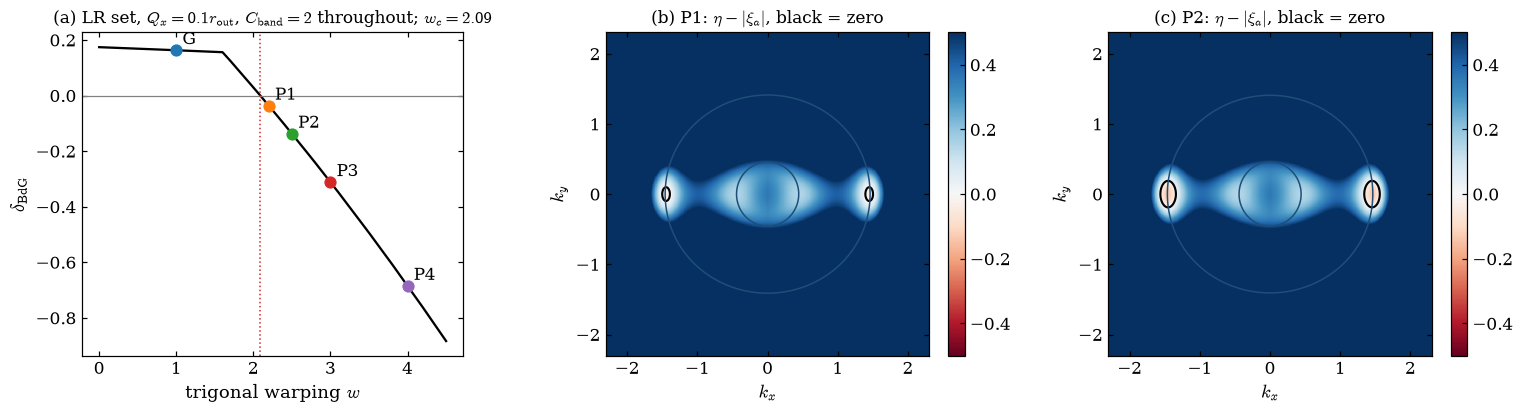

In [6]:
# ---- 1b. Lattice-resolved set: gap, pocket onset, pockets, scales
ws = np.linspace(0.0, 4.5, cfg["w_scan"])
dfw = pd.DataFrame([dict(w=w, **rc.kspace_summary(lr(w), cfg["nk_C"], cfg["nk_gap"])) for w in ws])
w_c = brentq(lambda w: rc.kspace_summary(lr(w), 61, cfg["nk_gap"])["delta_BdG"], 1.5, 3.0, xtol=2e-3)
print(f"C_band over the w scan: {np.unique(np.round(dfw.C, 4))};  pocket onset w_c = {w_c:.3f}")

kc = np.linspace(-2.3, 2.3, 921)
CX, CY = np.meshgrid(kc, kc, indexing="ij"); dk = kc[1] - kc[0]


def pockets(p):
    xs, xa, D = rc.bdg_fields(CX, CY, p)
    dl = np.sqrt(xs ** 2 + np.abs(D) ** 2) - np.abs(xa)
    lab, n = ndimage.label(dl < 0)
    out = []
    for i in range(1, n + 1):
        m = lab == i
        A = m.sum() * dk * dk
        out.append(dict(angle=float(np.degrees(np.arctan2(CY[m].mean(), CX[m].mean()))),
                        k=float(np.hypot(CX[m].mean(), CY[m].mean())), k_p=float(np.sqrt(A / np.pi))))
    return dl, out


# energy and length scales of the LR set (normal state at w = 0)
xs0 = rc.xi_normal(CX, CY, lr(0.0))
gx, gy = np.gradient(xs0, dk, dk)
on_fs = np.abs(xs0) < 0.02
vF = float(np.hypot(gx, gy)[on_fs].mean())
s_lr = rc.kspace_summary(lr(POINTS["G"]), cfg["nk_C"], cfg["nk_gap"])
EF = float(-rc.xi_normal(*rc.bz_grid(cfg["nk_gap"]), lr(0.0)).min())
eta_min = s_lr["eta_min"]
nuN = rc.normal_dos_at_EF(lr(0.0))
xi_sc = vF / eta_min
SCALES = dict(E_F=EF, v_F=vF, eta_min=eta_min, xi_SC=xi_sc, nu_N_per_site=nuN, w_c=w_c)
print({k: round(v, 4) for k, v in SCALES.items()})

rows = []
for name, w in POINTS.items():
    s = rc.kspace_summary(lr(w), cfg["nk_C"], cfg["nk_gap"])
    th = rc.kspace_thermal(lr(w), Nk=cfg["nk_thermal"])
    _, pk = pockets(lr(w))
    kp = max([x["k_p"] for x in pk], default=0.0)
    rows.append(dict(point=name, w=w, C_band=round(s["C"], 6), delta_BdG=s["delta_BdG"], n_pockets=len(pk),
                     k_p=kp, lambda_p=(2 * np.pi / kp if kp > 0 else np.inf),
                     pocket_angles=[round(x["angle"]) for x in pk], blocking_T0=th["blocking_T0"],
                     pocket_curvature=th["pocket_curvature"]))
dfp = pd.DataFrame(rows).set_index("point")
dfp.to_csv(OUT / "points_kspace.csv")
print(dfp.round(4).to_string())
SUMMARY["scales"] = SCALES
SUMMARY["points_kspace"] = dfp.reset_index().to_dict("records")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
ax[0].plot(dfw.w, dfw.delta_BdG, "k-")
ax[0].axhline(0, color="0.5", lw=0.8); ax[0].axvline(w_c, color="C3", ls=":", lw=1)
for name, w in POINTS.items():
    ax[0].plot(w, dfp.loc[name, "delta_BdG"], "o", ms=7)
    ax[0].annotate(name, (w, dfp.loc[name, "delta_BdG"]), xytext=(4, 4), textcoords="offset points")
ax[0].set_xlabel("trigonal warping $w$"); ax[0].set_ylabel(r"$\delta_{\rm BdG}$")
ax[0].set_title(rf"(a) LR set, $Q_x=0.1r_{{\rm out}}$, $C_{{\rm band}}=2$ throughout; $w_c={w_c:.2f}$")
for a, name in zip(ax[1:], ("P1", "P2")):
    dl, _ = pockets(lr(POINTS[name]))
    vm = 0.5
    im = a.pcolormesh(CX, CY, dl, cmap="RdBu", vmin=-vm, vmax=vm, shading="auto", rasterized=True)
    a.contour(CX, CY, dl, levels=[0], colors="k", linewidths=1.4)
    a.contour(CX, CY, rc.bdg_fields(CX, CY, lr(POINTS[name]))[0], levels=[0], colors="#1f4e79", linewidths=1)
    a.set_aspect("equal"); a.set_xlabel("$k_x$"); a.set_ylabel("$k_y$")
    a.set_title(rf"({'b' if name == 'P1' else 'c'}) {name}: $\eta-|\xi_a|$, black = zero")
    fig.colorbar(im, ax=a, fraction=0.046)
fig.tight_layout(); fig.savefig(FIG / "M1_model_pockets.pdf"); plt.show()

## 2. Real-space Hamiltonian and clean benchmarks

The hoppings are obtained by exact Fourier inversion of $\xi(\mathbf k)$ and $\Delta(\mathbf k)$ (normal range 2, pairing range 3). Two frames are used: the **gauge frame** ($c_{\mathbf r}\to e^{i\mathbf Q\cdot\mathbf r/2}c_{\mathbf r}$, uniform pairing, translation invariant, used on tori) and the **lab frame** (pairing phase $e^{i\mathbf Q\cdot\mathbf R_{\rm bond}}$, used with leads and domain walls). Checks: (i) the torus spectrum equals the Bloch spectrum on the commensurate $k$ grid; (ii) the two frames are unitarily equivalent; (iii) transport benchmarks, $T_{\rm edge}=|C|$ on a strip, $T_{\rm wall}=2|C|$ on a cylinder with two walls, an insulating cylinder, and the scattering Chern number $Q=\frac{1}{2\pi}\oint d\arg\det r(\phi)$ (Fulga, Hassler, Akhmerov, PRB 85, 165409 (2012)) with leads of decoupled chains and a twist $e^{i\phi}$ on the whole Nambu spinor.

In [7]:
val = {}
rec = rc.reconstruct_error(lr(POINTS["P2"]))
print("Fourier inversion:", rec); val["fourier"] = rec
assert rec["max_err"] < 1e-11 and rec["pairing_oddness"] < 1e-12

# torus spectrum = Bloch spectrum on the commensurate k grid
Lx_t, Wy_t = 8, 5
for name in ("G", "P2"):
    p = lr(POINTS[name])
    fs = rc.build_system(dict(p, kind="torus", Lx=Lx_t, Wy=Wy_t, frame="gauge"))
    H = fs.hamiltonian_submatrix(params=rc._params(0, 0))
    ev = np.sort(np.linalg.eigvalsh(H))
    Hy = np.sqrt(3) * Wy_t
    Ginv = np.linalg.inv(rc.GM.T)
    seen, kk = set(), []
    for m in range(-3 * Lx_t, 3 * Lx_t):
        for n in range(-3 * Wy_t, 3 * Wy_t):
            kv = np.array([2 * np.pi * m / Lx_t, 2 * np.pi * n / Hy])
            f = tuple(np.round(np.round(Ginv @ kv, 9) % 1.0, 8))
            if f not in seen:
                seen.add(f); kk.append(kv)
    eb = np.sort(np.concatenate([np.linalg.eigvalsh(rc.bloch_bdg(np.array(k[0]), np.array(k[1]), p)) for k in kk]))
    err = float(np.abs(eb - ev).max())
    print(f"{name}: torus {len(fs.sites)} sites, {len(kk)} k points, max |E_torus - E_Bloch| = {err:.2e}")
    assert len(kk) == len(fs.sites) and err < 1e-10
    val[f"torus_vs_bloch_{name}"] = err

# gauge frame = U^dag (lab frame) U
p = lr(POINTS["P2"])
Hl = rc.build_system(dict(p, kind="flake", Lx=10, Wy=6, frame="lab")).hamiltonian_submatrix(params=rc._params(0, 0))
fsg = rc.build_system(dict(p, kind="flake", Lx=10, Wy=6, frame="gauge"))
Hg = fsg.hamiltonian_submatrix(params=rc._params(0, 0))
x = np.array([s.pos[0] for s in fsg.sites])
Uv = np.ravel(np.column_stack([np.exp(1j * p["Qx"] * x / 2), np.exp(-1j * p["Qx"] * x / 2)]))
err = float(np.abs(Uv.conj()[:, None] * Hl * Uv[None, :] - Hg).max())
print(f"gauge = U^dag lab U: {err:.1e}"); assert err < 1e-12
val["gauge_vs_lab"] = err
SUMMARY["validation"] = val

Fourier inversion: {'max_err': 1.4210963135005665e-14, 'normal_range': 2, 'pairing_range': 3, 'n_normal': 19, 'n_pairing': 36, 'pairing_oddness': 1.1443916996305594e-16}
G: torus 80 sites, 80 k points, max |E_torus - E_Bloch| = 8.17e-14
P2: torus 80 sites, 80 k points, max |E_torus - E_Bloch| = 1.17e-13
gauge = U^dag lab U: 1.9e-15


In [8]:
# clean transport benchmarks (gapped point G unless stated)
Lb = 40 if RUN_MODE != "quick" else 32
bench = []
def T_of(key, U=0.0, seed=0):
    return rc.task_transport(key, [seed], U, [E0])[0]["T"][0]
pG = POINTS["G"]
bench.append(("strip, metal leads: T = |C| (edges)", T_of(cyl_key(pG, Lb, kind="strip")), 2.0))
bench.append(("cylinder: insulating bulk", T_of(cyl_key(pG, Lb)), 0.0))
bench.append(("cylinder, two sharp walls: T = 2|C|",
              T_of(rc.gkey(dict(LR, w=pG, kind="cylinder", Lx=Lb, Wy=20, frame="lab", buffer=BUFFER,
                                lead_type="metal", texture="wall2"))), 4.0))
bench.append(("normal limit (D0=0): T = number of Nambu modes",
              T_of(rc.gkey(dict(LR, w=pG, D0=0.0, kind="cylinder", Lx=16, Wy=9, frame="lab", buffer=BUFFER,
                                lead_type="metal"))), np.nan))
for chi in (-1.0, +1.0):
    r = rc.task_winding(cyl_key(pG, Lb, leads="chains", chi=chi), [0], 0.0, PHIS)[0]
    bench.append((f"scattering Chern number, chi={chi:+.0f}", r["Q"], -2 * chi))
    bench.append((f"   min_phi |det r|, chi={chi:+.0f}", r["min_abs_det_r"], 1.0))
rb = rc.task_bott(torus_key(pG, 16), [0], 0.0)[0]
bench.append(("Bott index (torus 16)", rb["bott"], 2 * LR["chi"]))
dfb = pd.DataFrame(bench, columns=["benchmark", "value", "expected"])
print(dfb.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
Q_CLEAN = int(round(dfb.value[dfb.benchmark.str.startswith("scattering Chern number, chi=-1")].iloc[0]))
BOTT_SIGN = int(np.sign(rb["bott"]) * np.sign(Q_CLEAN))
print(f"\nconventions: Q_scatt = +C_FHS (V17 Methods sign) = {Q_CLEAN} at G; Bott = {BOTT_SIGN:+d} x Q_scatt")
SUMMARY["benchmarks"] = dfb.to_dict("records"); SUMMARY["Q_clean"] = Q_CLEAN; SUMMARY["bott_sign"] = BOTT_SIGN

                                     benchmark   value  expected
           strip, metal leads: T = |C| (edges)  2.0011    2.0000
                     cylinder: insulating bulk  0.0021    0.0000
           cylinder, two sharp walls: T = 2|C|  3.9986    4.0000
normal limit (D0=0): T = number of Nambu modes 20.0000       NaN
               scattering Chern number, chi=-1  2.0000    2.0000
                       min_phi |det r|, chi=-1  0.9995    1.0000
               scattering Chern number, chi=+1 -2.0000   -2.0000
                       min_phi |det r|, chi=+1  0.9995    1.0000
                         Bott index (torus 16) -2.0000   -2.0000

conventions: Q_scatt = +C_FHS (V17 Methods sign) = 2 at G; Bott = -1 x Q_scatt


## 3. Bridge to the V17 thermal kernel

(a) **k space.** For the two-band BdG spectrum $E_\pm=\xi_a\pm\eta$ with lower-band curvature $\Omega$, the Fermi-sea Hall function is $s(E)=\frac1{2\pi}\int\Omega\,[\Theta(E-E_-)-\Theta(E-E_+)]$ and
$\kappa_{xy}/(Tq_M)=\frac{3}{\pi^2\theta^2}\int dE\,E^2(-f')\,s(E)$. This must equal the V17 branch-weight form $\frac1{2\pi}\int\Omega\,\mathcal W_{\mathbf Q}$ with the exact kernel $\mathcal G$ (Eqs. kernel-G, branch-weight), and its $T\to0$ limit is Eq. (curvature-blocking). For the gapped point the plateau-error bound (Eq. plateau-error-bound) is checked at every temperature.

(b) **Real space.** Kubo-Bastin $s(E)$ of the lattice BdG Hamiltonian from Kwant's KPM, sampled in the central half of an open flake. Sign and normalization are calibrated on the square-lattice $p+ip$ anchor of V17 Methods ($C=+1$).

G: C_band=2.0000  T->0 (curvature blocking) = 2.0000  pocket curvature = 0.0000  max|W_Q - s(E) conv| = 9.8e-03
P1: C_band=2.0000  T->0 (curvature blocking) = 1.9089  pocket curvature = 0.0911  max|W_Q - s(E) conv| = 9.1e-03
P2: C_band=2.0000  T->0 (curvature blocking) = 1.7115  pocket curvature = 0.2885  max|W_Q - s(E) conv| = 8.2e-03
P3: C_band=2.0000  T->0 (curvature blocking) = 1.4848  pocket curvature = 0.5152  max|W_Q - s(E) conv| = 7.0e-03
P4: C_band=2.0000  T->0 (curvature blocking) = 1.2219  pocket curvature = 0.7781  max|W_Q - s(E) conv| = 6.0e-03
G: plateau-error bound |kappa/(T q_M) - C| <= A_Omega [1 - G(delta/2 theta)] holds at all theta: True   (A_Omega = 3.497, delta = 0.1629)


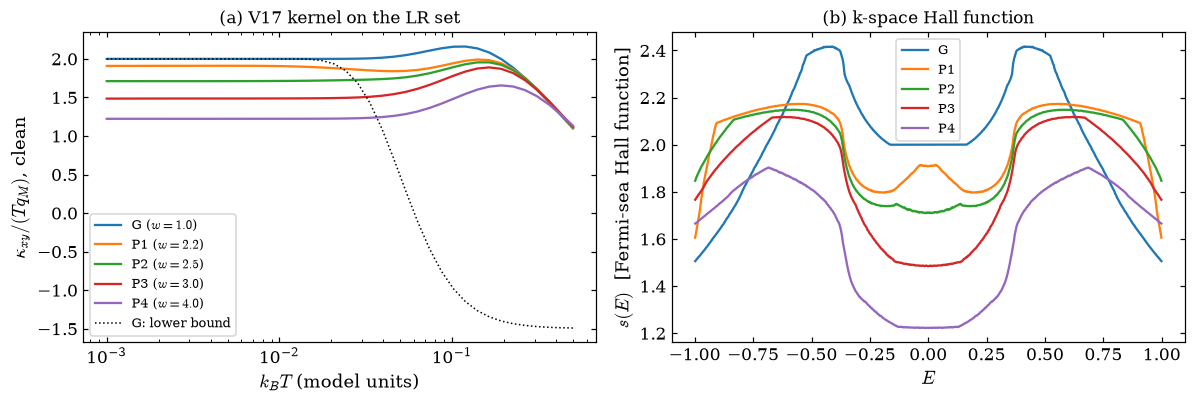

In [9]:
thetas = np.geomspace(1e-3, 0.5, 40)
E_conv = np.linspace(-30, 30, 30001)
KT, kchk = {}, {}
for name in cfg["points"]:
    r = rc.kspace_thermal(lr(POINTS[name]), Nk=cfg["nk_thermal"], thetas=thetas, E_grid=E_conv)
    KT[name] = r
    kchk[name] = float(np.abs(r["kappa_WQ"] - r["kappa_conv"]).max())
    print(f"{name}: C_band={r['C_band']:.4f}  T->0 (curvature blocking) = {r['blocking_T0']:.4f}  "
          f"pocket curvature = {r['pocket_curvature']:.4f}  max|W_Q - s(E) conv| = {kchk[name]:.1e}")
rG = KT["G"]
bound = rG["A_Omega"] * (1 - rc.G_kernel(rG["delta_BdG"] / (2 * thetas)))
ok_bound = bool(np.all(np.abs(rG["kappa_WQ"] - rG["C_band"]) <= bound + 1e-9))
print(f"G: plateau-error bound |kappa/(T q_M) - C| <= A_Omega [1 - G(delta/2 theta)] holds at all theta: {ok_bound}"
      f"   (A_Omega = {rG['A_Omega']:.3f}, delta = {rG['delta_BdG']:.4f})")
SUMMARY["bridge_kspace"] = dict(identity_max_dev=kchk, bound_holds=ok_bound,
                                T0={k: v["blocking_T0"] for k, v in KT.items()})

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, r in KT.items():
    ax[0].semilogx(thetas, r["kappa_WQ"], label=rf"{name} ($w={POINTS[name]}$)")
ax[0].plot(thetas, rG["C_band"] - bound, "k:", lw=1, label="G: lower bound")
ax[0].set_xlabel(r"$k_BT$ (model units)"); ax[0].set_ylabel(r"$\kappa_{xy}/(Tq_M)$, clean")
ax[0].set_title("(a) V17 kernel on the LR set"); ax[0].legend()
m = np.abs(E_conv) < 1.0
for name, r in KT.items():
    ax[1].plot(E_conv[m], r["s_E"][m], label=name)
ax[1].set_xlabel("$E$"); ax[1].set_ylabel("$s(E)$  [Fermi-sea Hall function]"); ax[1].legend()
ax[1].set_title("(b) k-space Hall function")
fig.tight_layout(); fig.savefig(FIG / "B1_kernel_bridge.pdf"); plt.show()

[KPM anchor] 2 tasks, 2 computed: 0.1 min
p+ip anchor (C=+1): raw s(0) = -1.006, s(0.3) = -1.006  ->  sign factor -1


/home/kumar/anaconda3/envs/physics/lib/python3.11/site-packages/kwant/kpm.py:1009: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp((energy - mu) / temperature))
/home/kumar/anaconda3/envs/physics/lib/python3.11/site-packages/kwant/kpm.py:1009: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp((energy - mu) / temperature))
/home/kumar/anaconda3/envs/physics/lib/python3.11/site-packages/kwant/kpm.py:1009: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp((energy - mu) / temperature))
/home/kumar/anaconda3/envs/physics/lib/python3.11/site-packages/kwant/kpm.py:1009: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp((energy - mu) / temperature))
/home/kumar/anaconda3/envs/physics/lib/python3.11/site-packages/kwant/kpm.py:1009: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp((energy - mu) / temperature))
/home/kumar/anaconda3/envs/physics/lib/python3.11/site-packages/kwant/kpm.py:1009: Runtime

[KPM G] 8 tasks, 8 computed: 7.5 min
[KPM P2] 8 tasks, 8 computed: 7.5 min


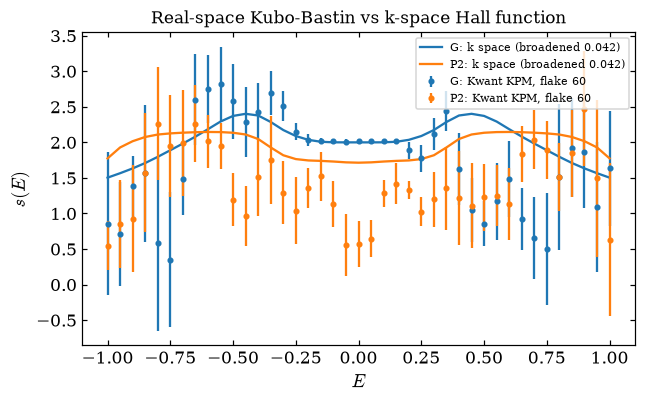

s(0) real space: {'G': [2.0134341254849004, 0.03132350592613458], 'P2': [0.5761908449309842, 0.32328379089953185]}  k space: {'G': 1.9999999999999851, 'P2': 1.711524584153582}


In [10]:
# real-space Kubo-Bastin (KPM): calibration on the p+ip anchor, then the LR flakes
E_k = list(np.linspace(-1.0, 1.0, 41))
temp_k = 0.002
anchor_key = rc.gkey(dict(kind="pip_flake", Lx=cfg["kpm_flake"], D=1.0, mu_bar=2.0))
anc = run_tasks("task_kpm_sxy", [dict(key=anchor_key, U=0.0, seed=s, energies=[0.0, 0.3], num_moments=600,
                                      num_vectors=cfg["nvec_kpm"], temperature=0.01) for s in range(2)], "KPM anchor")
anc = np.mean(anc, axis=0)
KPM_SIGN = float(np.sign(anc[0]))
print(f"p+ip anchor (C=+1): raw s(0) = {anc[0]:+.3f}, s(0.3) = {anc[1]:+.3f}  ->  sign factor {KPM_SIGN:+.0f}")

kpm = {}
for name in ("G", "P2"):
    key = rc.gkey(dict(lr(POINTS[name]), kind="flake", Lx=cfg["kpm_flake"], Wy=wy(cfg["kpm_flake"]), frame="lab"))
    out = run_tasks("task_kpm_sxy", [dict(key=key, U=0.0, seed=s, energies=E_k, num_moments=cfg["M_kpm"],
                                          num_vectors=cfg["nvec_kpm"], temperature=temp_k)
                                     for s in range(cfg["kpm_tasks"])], f"KPM {name}")
    out = np.array(out) / KPM_SIGN
    kpm[name] = (out.mean(0), out.std(0) / np.sqrt(len(out)))

# spectral half-width for the Jackson resolution pi*a/M
import scipy.sparse.linalg as sla
_fs = rc.cached_system(rc.gkey(dict(lr(POINTS["G"]), kind="flake", Lx=16, Wy=9, frame="lab")))
a_half = abs(float(sla.eigsh(_fs.hamiltonian_submatrix(sparse=True, params=rc._params(0, 0)), k=1, which="LM")[0][0]))
sig = np.pi * a_half / cfg["M_kpm"]
fig, ax = plt.subplots(figsize=(6, 3.8))
for c, name in zip(("C0", "C1"), ("G", "P2")):
    sE = KT[name]["s_E"]
    ker = np.exp(-0.5 * ((E_conv[:, None] - np.array(E_k)[None, :]) / sig) ** 2)
    sb = (ker * sE[:, None]).sum(0) / ker.sum(0)
    ax.plot(E_k, sb, color=c, lw=1.5, label=f"{name}: k space (broadened {sig:.3f})")
    mu_, se_ = kpm[name]
    ax.errorbar(E_k, mu_, yerr=se_, fmt="o", ms=3, color=c, label=f"{name}: Kwant KPM, flake {cfg['kpm_flake']}")
ax.set_xlabel("$E$"); ax.set_ylabel("$s(E)$"); ax.legend(fontsize=7)
ax.set_title("Real-space Kubo-Bastin vs k-space Hall function")
fig.tight_layout(); fig.savefig(FIG / "B2_kpm_bridge.pdf"); plt.show()
i0 = len(E_k) // 2
SUMMARY["bridge_kpm"] = dict(anchor_raw=anc.tolist(), sign=KPM_SIGN, resolution=sig,
                             s0={k: [float(v[0][i0]), float(v[1][i0])] for k, v in kpm.items()},
                             s0_kspace={k: float(np.interp(0.0, E_conv, KT[k]["s_E"])) for k in ("G", "P2")})
print("s(0) real space:", SUMMARY["bridge_kpm"]["s0"], " k space:", SUMMARY["bridge_kpm"]["s0_kspace"])

## 4. Calibration: what a class-D thermal metal looks like in this pipeline

Square-lattice $p+ip$ (V17 anchor, $C=\pm1$ either side of $\mu=4t$) with uniform random chemical potential $\mu\in[\bar\mu-U,\bar\mu+U]$. Around $\bar\mu=4t$ the disorder writes random $\pm1$ domains whose walls percolate, the established route to the Majorana metal (Zakharov et al.); $\bar\mu=2t$, $U=t$ is the gapped control. The metallic slope $b$ in $\langle g\rangle=a+b\ln L$ measured here, in this code's normalization, is the reference for Section 6.

[calibration g(L)] 108 tasks, 108 computed: 0.5 min
[calibration Q] 12 tasks, 12 computed: 1.0 min
metal: mu=4t, U=3t, D=t     : <g>(L) = [1.583 1.726 1.775 2.015 2.07  2.077];  d<g>/dlnL = +0.093 +- 0.170
metal: mu=4t, U=3t, D=t/2   : <g>(L) = [1.966 2.165 2.223 2.31  2.466 2.542];  d<g>/dlnL = +0.338 +- 0.133
insulator: mu=2t, U=t, D=t  : <g>(L) = [0. 0. 0. 0. 0. 0.];  d<g>/dlnL = -0.000 +- 0.000


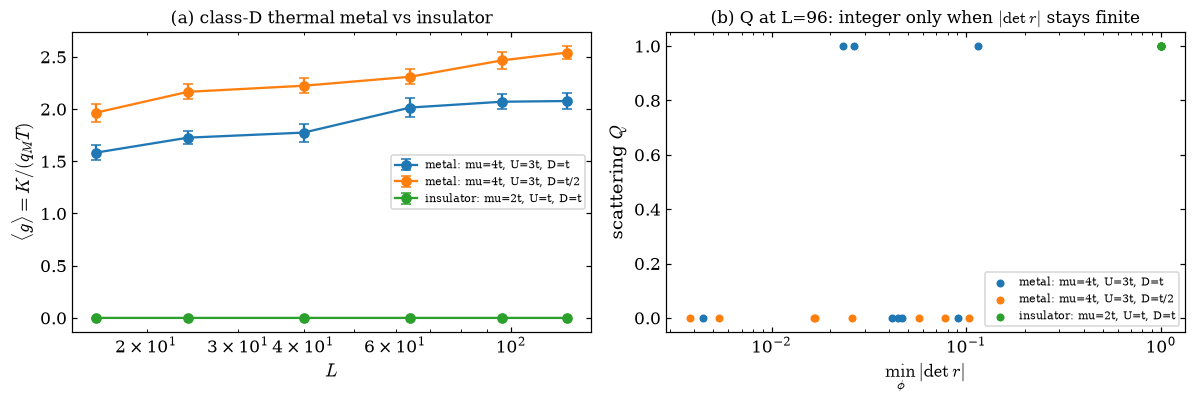

reference metallic slope (this normalization): 0.216


In [11]:
CAL = {"metal: mu=4t, U=3t, D=t": dict(mu_bar=4.0, U=3.0, D=1.0),
       "metal: mu=4t, U=3t, D=t/2": dict(mu_bar=4.0, U=3.0, D=0.5),
       "insulator: mu=2t, U=t, D=t": dict(mu_bar=2.0, U=1.0, D=1.0)}
kws, meta = [], []
for lab, c in CAL.items():
    for L in cfg["calib_L"]:
        key = rc.gkey(dict(kind="pip_cylinder", Lx=L, Wy=L, D=c["D"], mu_bar=c["mu_bar"]))
        for ch in chunks(range(1, cfg["calib_seeds"] + 1), 4):
            kws.append(dict(key=key, seeds=ch, U=c["U"], E_list=[E0])); meta.append((lab, L))
res = run_tasks("task_transport", kws, "calibration g(L)")
rows = [dict(model=lab, L=L, seed=r["seed"], g=r["T"][0]) for (lab, L), rr in zip(meta, res) for r in rr]
dfc = pd.DataFrame(rows); dfc.to_csv(OUT / "calibration_g.csv", index=False)

Lw = cfg["calib_L"][-2]
kws = [dict(key=rc.gkey(dict(kind="pip_cylinder", Lx=Lw, Wy=Lw, D=c["D"], mu_bar=c["mu_bar"])), seeds=ch,
            U=c["U"], phis=PHIS) for lab, c in CAL.items() for ch in chunks(range(1, min(8, cfg["calib_seeds"]) + 1), 2)]
resw = run_tasks("task_winding", kws, "calibration Q")
labs = [lab for lab in CAL for _ in chunks(range(1, min(8, cfg["calib_seeds"]) + 1), 2)]
dfcq = pd.DataFrame([dict(r, model=lab) for lab, rr in zip(labs, resw) for r in rr])


def slope_lnL(df, n_top=3, n_boot=300, col="g", rng=np.random.default_rng(1)):
    # <col> = a + b ln L over the n_top largest sizes; bootstrap over samples at each L
    Ls = sorted(df.L.unique())[-n_top:]
    groups = [df[df.L == L][col].values for L in Ls]
    if len(Ls) < 2 or min(len(gr) for gr in groups) < 1:
        return np.nan, np.nan
    fit = lambda ms: np.polyfit(np.log(Ls), ms, 1)[0]
    b = fit([gr.mean() for gr in groups])
    bs = [fit([rng.choice(gr, len(gr)).mean() for gr in groups]) for _ in range(n_boot)]
    return float(b), float(np.std(bs))


CAL_SLOPES = {}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for lab in CAL:
    d = dfc[dfc.model == lab]
    agg = d.groupby("L").g.agg(["mean", "std", "count"])
    ax[0].errorbar(agg.index, agg["mean"], yerr=agg["std"] / np.sqrt(agg["count"]), fmt="o-", capsize=3, label=lab)
    b, eb = slope_lnL(d)
    CAL_SLOPES[lab] = (b, eb)
    print(f"{lab:28s}: <g>(L) = {np.round(agg['mean'].values, 3)};  d<g>/dlnL = {b:+.3f} +- {eb:.3f}")
ax[0].set_xscale("log"); ax[0].set_xlabel("$L$"); ax[0].set_ylabel(r"$\langle g\rangle = K/(q_MT)$")
ax[0].legend(fontsize=7); ax[0].set_title("(a) class-D thermal metal vs insulator")
for lab in CAL:
    d = dfcq[dfcq.model == lab]
    ax[1].scatter(d.min_abs_det_r, d.Q, label=lab, s=18)
ax[1].set_xscale("log"); ax[1].set_xlabel(r"$\min_\phi|\det r|$"); ax[1].set_ylabel("scattering $Q$")
ax[1].set_title(f"(b) Q at L={Lw}: integer only when $|\\det r|$ stays finite"); ax[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "C1_calibration.pdf"); plt.show()
METAL_SLOPE_REF = float(np.nanmean([v[0] for k, v in CAL_SLOPES.items() if k.startswith("metal")]))
print(f"reference metallic slope (this normalization): {METAL_SLOPE_REF:.3f}")
SUMMARY["calibration"] = dict(slopes=CAL_SLOPES, metal_slope_ref=METAL_SLOPE_REF,
                              g_by_L=dfc.groupby(["model", "L"]).g.mean().round(4).to_dict().__repr__())

## 5. Main scan: disorder ensembles across the pocket onset

For each warping point and disorder strength $U$ (uniform on-site potential in $[-U,U]$, $\tau_z$ channel, class D preserved):
* $g(L)=\mathcal{T}_{R\leftarrow L}(E\to0)$ on square cylinders (periodic in $y$, no edges, metal leads), ensemble mean and typical value;
* scattering Chern number $Q$ and $\min_\phi|\det r|$ (chain leads) at the sizes `L_wind`;
* Bott index and low-lying level counts on small tori;
* KPM density of states at $E=0$ on a large torus, in units of the normal-state BdG value $2\nu_N$.

The Born mean free path $\ell=v_F\tau$, $1/\tau=2\pi\nu_N U^2/3$, is printed so that $L/\ell$ can be judged.

In [12]:
PTS, ULIST = cfg["points"], cfg["U"]
for U in ULIST[1:]:
    tau_inv = 2 * np.pi * nuN * U ** 2 / 3
    print(f"U = {U:4.2f}:  1/tau = {tau_inv:.4f}  (eta_min = {eta_min:.3f}),  l_Born = {vF / tau_inv:8.1f}  "
          f"->  L_max/l = {max(cfg['L']) * tau_inv / vF:.2f}")

# transport g(L)
kws, meta = [], []
for p in PTS:
    for U in ULIST:
        for L in cfg["L"]:
            for ch in chunks(seeds_for(U, cfg["seeds"]), 4):
                kws.append(dict(key=cyl_key(POINTS[p], L), seeds=ch, U=U, E_list=[E0])); meta.append((p, U, L))
print(f"transport: {sum(len(k['seeds']) for k in kws)} solves")
res = run_tasks("task_transport", kws, "main g(L)")
dfg = pd.DataFrame([dict(point=p, w=POINTS[p], U=U, L=L, seed=r["seed"], g=r["T"][0])
                    for (p, U, L), rr in zip(meta, res) for r in rr])
dfg.to_csv(OUT / "main_g.csv", index=False)

# scattering Chern number
kws, meta = [], []
for p in PTS:
    for U in ULIST:
        for L in cfg["L_wind"]:
            for ch in chunks(seeds_for(U, cfg["seeds_wind"]), 2):
                kws.append(dict(key=cyl_key(POINTS[p], L, leads="chains"), seeds=ch, U=U, phis=PHIS)); meta.append((p, U, L))
print(f"winding: {sum(len(k['seeds']) for k in kws) * len(PHIS)} solves")
res = run_tasks("task_winding", kws, "main Q")
dfq = pd.DataFrame([dict(r, point=p, w=POINTS[p], U=U, L=L) for (p, U, L), rr in zip(meta, res) for r in rr])
dfq.to_csv(OUT / "main_Q.csv", index=False)

# Bott index
kws, meta = [], []
for p in PTS:
    for U in ULIST:
        for L in cfg["L_bott"]:
            for ch in chunks(seeds_for(U, cfg["seeds_bott"]), 2):
                kws.append(dict(key=torus_key(POINTS[p], L), seeds=ch, U=U)); meta.append((p, U, L))
res = run_tasks("task_bott", kws, "main Bott")
dfbt = pd.DataFrame([dict({k: v for k, v in r.items() if k != "n_lt"}, point=p, w=POINTS[p], U=U, L=L,
                          n_lt_0p01=r["n_lt"][1]) for (p, U, L), rr in zip(meta, res) for r in rr])
dfbt["bott_signed"] = dfbt.bott * BOTT_SIGN
dfbt.to_csv(OUT / "main_bott.csv", index=False)

# KPM density of states near E = 0
E_dos = list(np.linspace(-0.4, 0.4, 81))
kws = [dict(key=torus_key(POINTS[p], cfg["L_dos"]), seed=(0 if U == 0 else 1), U=U, energies=E_dos,
            num_moments=cfg["M_dos"], num_vectors=cfg["nvec_dos"]) for p in PTS for U in ULIST]
res = run_tasks("task_kpm_dos", kws, "main DOS")
DOS = {(p, U): np.asarray(r) for (p, U), r in zip([(p, U) for p in PTS for U in ULIST], res)}
rho_norm = 2 * nuN                     # normal-state BdG DOS per site at E = 0 (electron + hole)
dfd = pd.DataFrame([dict(point=p, w=POINTS[p], U=U, rho0=float(np.interp(0.0, E_dos, DOS[(p, U)])) / rho_norm)
                    for p in PTS for U in ULIST])
dfd.to_csv(OUT / "main_dos0.csv", index=False)
print(dfd.pivot(index="point", columns="U", values="rho0").round(3).to_string())

U = 0.25:  1/tau = 0.0132  (eta_min = 0.265),  l_Born =    200.0  ->  L_max/l = 0.80
U = 0.50:  1/tau = 0.0526  (eta_min = 0.265),  l_Born =     50.0  ->  L_max/l = 3.20
U = 1.00:  1/tau = 0.2105  (eta_min = 0.265),  l_Born =     12.5  ->  L_max/l = 12.80
U = 1.50:  1/tau = 0.4736  (eta_min = 0.265),  l_Born =      5.6  ->  L_max/l = 28.80
U = 2.00:  1/tau = 0.8419  (eta_min = 0.265),  l_Born =      3.1  ->  L_max/l = 51.21
U = 3.00:  1/tau = 1.8943  (eta_min = 0.265),  l_Born =      1.4  ->  L_max/l = 115.22
transport: 4350 solves


/home/kumar/anaconda3/envs/physics/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[main g(L)] 1110 tasks, 1110 computed: 144.9 min
winding: 17520 solves
[main Q] 370 tasks, 370 computed: 241.4 min
[main Bott] 375 tasks, 375 computed: 325.9 min
[main DOS] 35 tasks, 35 computed: 1.4 min
U       0.00   0.25   0.50   1.00   1.50   2.00   3.00
point                                                 
G      0.000  0.000  0.000  0.000  0.001  0.028  0.295
P1     0.099  0.101  0.100  0.110  0.145  0.225  0.333
P2     0.098  0.117  0.122  0.145  0.196  0.266  0.361
P3     0.125  0.133  0.137  0.153  0.203  0.280  0.411
P4     0.208  0.183  0.182  0.202  0.272  0.357  0.501


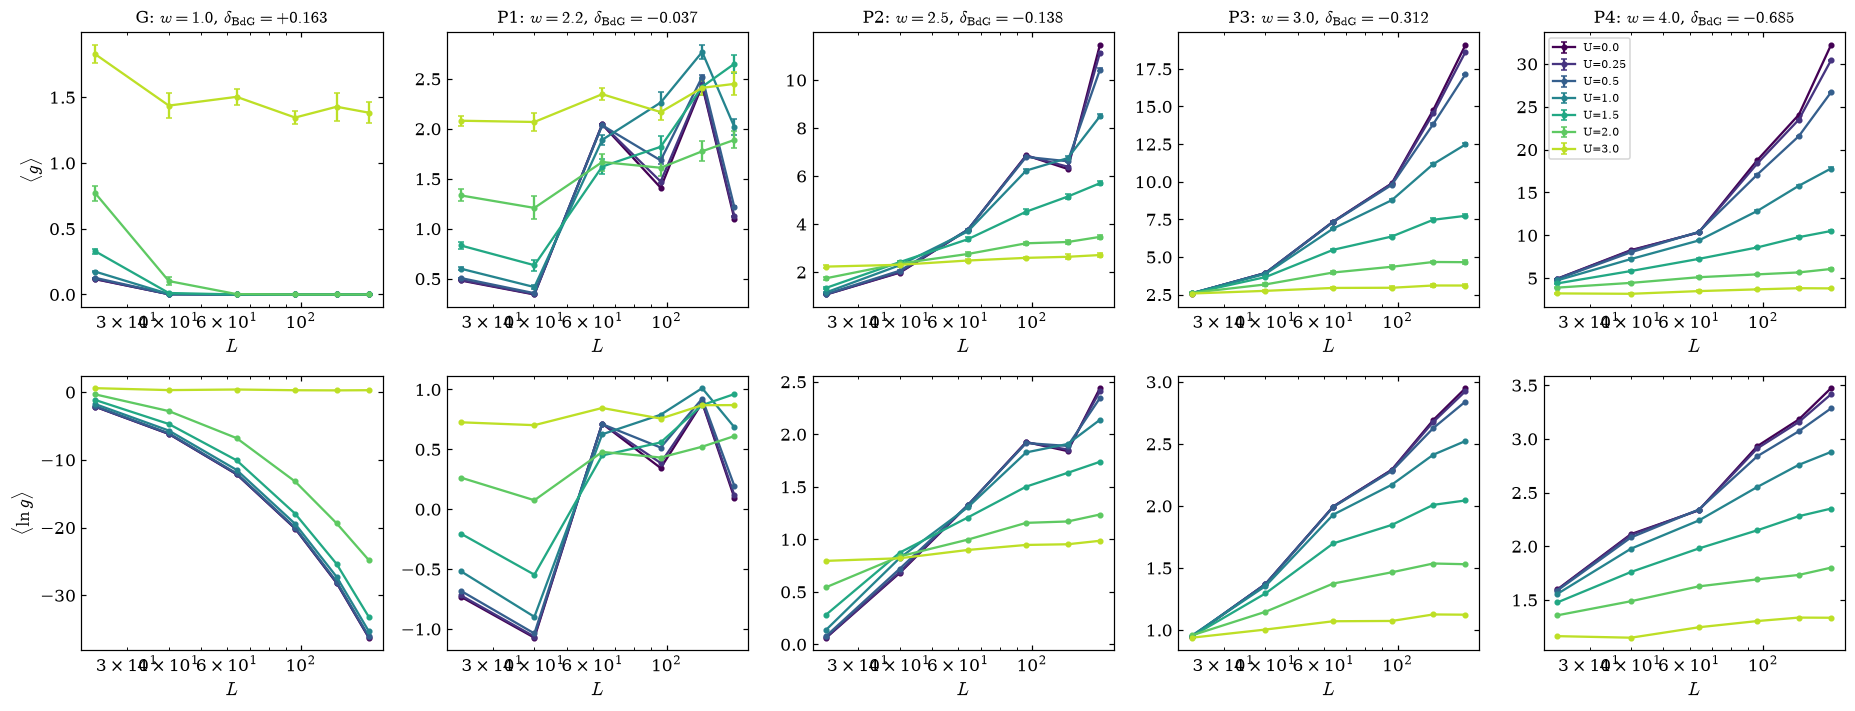

/tmp/ipykernel_8674/253124618.py:22: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f = d.groupby("U").apply(lambda x: np.mean((np.round(x.Q) == Q_CLEAN) & (x.min_abs_det_r > 0.2)))
/tmp/ipykernel_8674/253124618.py:22: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f = d.groupby("U").apply(lambda x: np.mean((np.round(x.Q) == Q_CLEAN) & (x.min_abs_det_r > 0.2)))
/tmp/ipykernel_8674/253124618.py:22: FutureWarning: DataFr

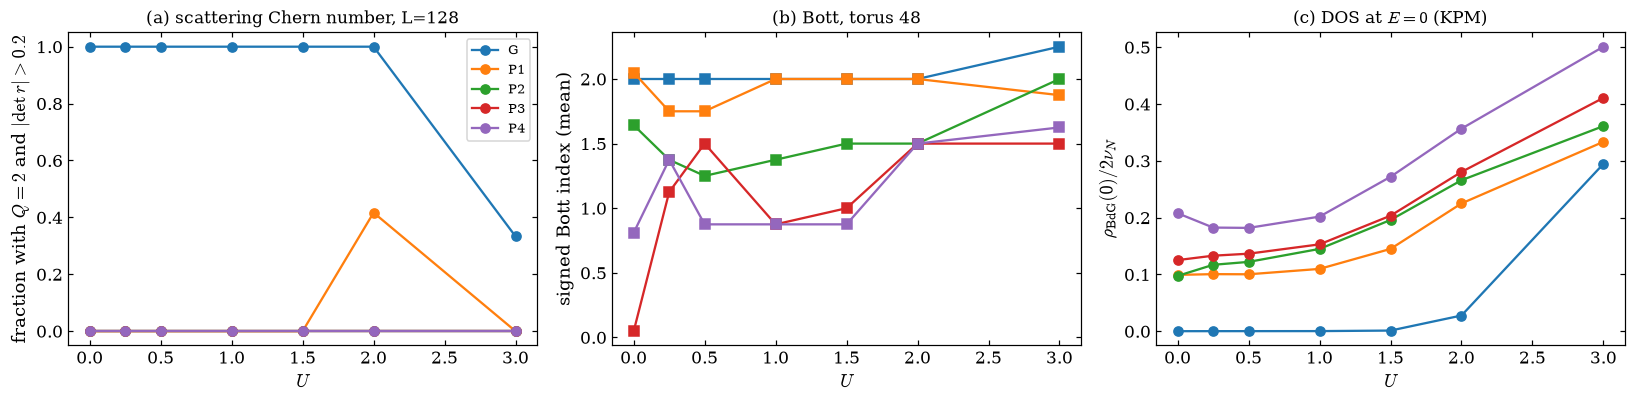

In [13]:
cols = plt.cm.viridis(np.linspace(0, 0.9, len(ULIST)))
fig, ax = plt.subplots(2, len(PTS), figsize=(3.4 * len(PTS), 6.6), squeeze=False)
for j, p in enumerate(PTS):
    for c, U in zip(cols, ULIST):
        d = dfg[(dfg.point == p) & (dfg.U == U)]
        agg = d.groupby("L").g.agg(["mean", "std", "count"])
        ax[0, j].errorbar(agg.index, agg["mean"], yerr=agg["std"] / np.sqrt(agg["count"]), fmt="o-", ms=3,
                          color=c, capsize=2, label=f"U={U}")
        lg = d.assign(lg=np.log(d.g.clip(lower=1e-300))).groupby("L").lg.mean()
        ax[1, j].plot(lg.index, lg.values, "o-", ms=3, color=c)
    ax[0, j].set_xscale("log"); ax[0, j].set_title(rf"{p}: $w={POINTS[p]}$, $\delta_{{\rm BdG}}={dfp.loc[p, 'delta_BdG']:+.3f}$")
    ax[0, j].set_xlabel("$L$"); ax[1, j].set_xlabel("$L$")
    ax[1, j].set_xscale("log")
ax[0, 0].set_ylabel(r"$\langle g\rangle$"); ax[1, 0].set_ylabel(r"$\langle\ln g\rangle$")
ax[0, -1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "D1_g_scaling.pdf"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for p in PTS:
    d = dfq[dfq.L == max(cfg["L_wind"])]
    d = d[d.point == p]
    f = d.groupby("U").apply(lambda x: np.mean((np.round(x.Q) == Q_CLEAN) & (x.min_abs_det_r > 0.2)))
    ax[0].plot(f.index, f.values, "o-", label=p)
    b = dfbt[(dfbt.point == p) & (dfbt.L == max(cfg["L_bott"]))].groupby("U").bott_signed.mean()
    ax[1].plot(b.index, b.values, "s-", label=p)
    r0 = dfd[dfd.point == p]
    ax[2].plot(r0.U, r0.rho0, "o-", label=p)
ax[0].set_xlabel("$U$"); ax[0].set_ylabel(f"fraction with $Q={Q_CLEAN}$ and $|\\det r|>0.2$")
ax[0].set_title(f"(a) scattering Chern number, L={max(cfg['L_wind'])}"); ax[0].legend()
ax[1].set_xlabel("$U$"); ax[1].set_ylabel("signed Bott index (mean)"); ax[1].set_title(f"(b) Bott, torus {max(cfg['L_bott'])}")
ax[2].set_xlabel("$U$"); ax[2].set_ylabel(r"$\rho_{\rm BdG}(0)/2\nu_N$"); ax[2].set_title("(c) DOS at $E=0$ (KPM)")
fig.tight_layout(); fig.savefig(FIG / "D2_Q_bott_dos.pdf"); plt.show()

## 6. Classification and the $(w,U)$ phase diagram

Per point:
* metallic slope $b=d\langle g\rangle/d\ln L$ over the three largest sizes (bootstrap error), compared with the calibrated reference;
* localization slope $d\langle\ln g\rangle/dL$;
* $f_Q$: fraction of samples at the largest winding size with $Q=Q_{\rm clean}$ and $\min|\det r|>0.2$;
* $\rho_0=\rho_{\rm BdG}(0)/2\nu_N$.

Guards against false positives: (i) *localized* requires $\langle\ln g\rangle$ to fall by at least one e-fold across the three largest sizes with $\langle g\rangle_{L_{\max}}<0.2$; (ii) *metallic* and *localized* verdicts are only meaningful for $L_{\max}\ge3\ell_{\rm Born}$, otherwise the point is labelled quasi-ballistic (the H3 regime of V17); (iii) *gapless* means a DOS excess $\rho_0-\rho_0^{\rm clean\,G}\ge0.02$ when the KPM resolution is below $\delta_{\rm BdG}^G/3$, and otherwise exact levels with $|E|<0.01$ on the Bott tori; (iv) the headline H1 label is reserved for points whose clean spectrum already has pockets, separating it from disorder-induced subgap tails.

Labels: **gapped, quantized**; **GAPLESS BUT QUANTIZED (pockets)** (H1); **gapless (disorder tails), quantized**; **thermal metal** ($b>2\sigma_b$ and $\langle g\rangle_{L_{\max}}>0.5$, or $b\ge0$ within error with $\langle g\rangle_{L_{\max}}>1$; H2); **localized, other integer**; **clean ballistic (H3)** / **quasi-ballistic**; **crossover** otherwise.

KPM DOS resolution 0.028 vs delta_G/3 = 0.054: resolved
point   w    U  ell_Born  L_over_ell  g_Lmax  slope_lnL  slope_err  lng_drop    f_Q  Q_mode   rho0  rho0_excess  zero_levels_torus                               label
    G 1.0 0.00       inf      0.0000  0.0000        NaN        NaN  -16.1160 1.0000     2.0 0.0002       0.0000               0.00                   gapped, quantized
    G 1.0 0.25  199.9696      0.8001  0.0000    -0.0000     0.0000  -16.1009 1.0000     2.0 0.0002       0.0000               0.00                   gapped, quantized
    G 1.0 0.50   49.9924      3.2005  0.0000    -0.0000     0.0000  -16.0591 1.0000     2.0 0.0003       0.0001               0.00                   gapped, quantized
    G 1.0 1.00   12.4981     12.8019  0.0000    -0.0000     0.0000  -15.8666 1.0000     2.0 0.0003       0.0001               0.00                   gapped, quantized
    G 1.0 1.50    5.5547     28.8044  0.0000    -0.0000     0.0000  -15.2450 1.0000     2.0 0.0013       0.00

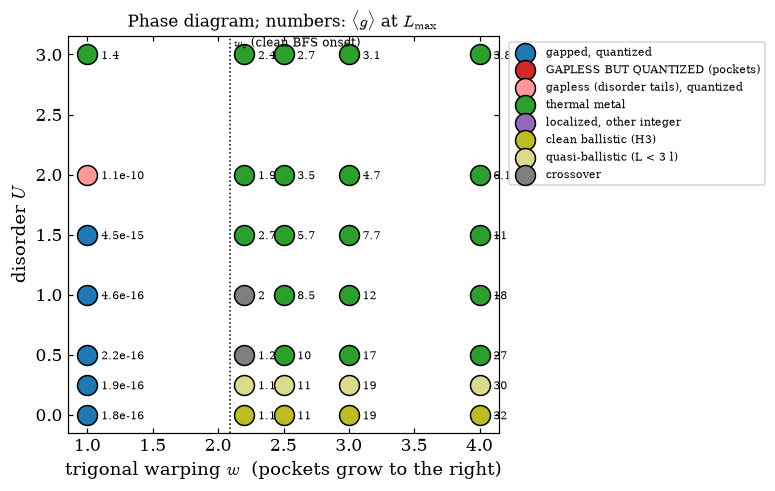


=== VERDICT (pilot) ===
gapped, quantized                     : [['G', 0.0], ['G', 0.25], ['G', 0.5], ['G', 1.0], ['G', 1.5]]
GAPLESS BUT QUANTIZED (pockets)       : none
gapless (disorder tails), quantized   : [['G', 2.0]]
thermal metal                         : [['G', 3.0], ['P1', 1.5], ['P1', 2.0], ['P1', 3.0], ['P2', 0.5], ['P2', 1.0], ['P2', 1.5], ['P2', 2.0], ['P2', 3.0], ['P3', 0.5], ['P3', 1.0], ['P3', 1.5], ['P3', 2.0], ['P3', 3.0], ['P4', 0.5], ['P4', 1.0], ['P4', 1.5], ['P4', 2.0], ['P4', 3.0]]
localized, other integer              : none
clean ballistic (H3)                  : [['P1', 0.0], ['P2', 0.0], ['P3', 0.0], ['P4', 0.0]]
quasi-ballistic (L < 3 l)             : [['P1', 0.25], ['P2', 0.25], ['P3', 0.25], ['P4', 0.25]]
crossover                             : [['P1', 0.5], ['P1', 1.0]]
metallic slopes d<g>/dlnL: [ 0.082  1.648  0.546  0.566  6.747  4.3    2.313  0.507  0.226 14.371
  7.302  2.745  0.621  0.303 18.632  9.715  3.771  1.211  0.233]  vs calibrated class-D 

In [14]:
DELTA_G = float(dfp.loc["G", "delta_BdG"])
KPM_RES = np.pi * a_half / cfg["M_dos"]                    # Jackson resolution of the DOS
DOS_RESOLVED = KPM_RES < DELTA_G / 3
RHO_BASE = float(dfd[(dfd.point == "G") & (dfd.U == 0)].rho0.iloc[0])   # clean gapped baseline (KPM leakage)
print(f"KPM DOS resolution {KPM_RES:.3f} vs delta_G/3 = {DELTA_G / 3:.3f}: "
      f"{'resolved' if DOS_RESOLVED else 'NOT resolved, falling back to exact torus level counts'}")


def ell_born(U):
    return np.inf if U == 0 else vF / (2 * np.pi * nuN * U ** 2 / 3)


def classify(p, U):
    d = dfg[(dfg.point == p) & (dfg.U == U)]
    Ls = sorted(d.L.unique())
    gmax = d[d.L == Ls[-1]].g.mean()
    b, eb = slope_lnL(d) if U > 0 else (np.nan, np.nan)
    lg = d.assign(lg=np.log(d.g.clip(lower=1e-300))).groupby("L").lg.mean()
    drop = float(lg.values[-1] - lg.values[-min(3, len(lg))]) if len(lg) >= 2 else 0.0
    dq = dfq[(dfq.point == p) & (dfq.U == U) & (dfq.L == max(cfg["L_wind"]))]
    fQ = float(np.mean((np.round(dq.Q) == Q_CLEAN) & (dq.min_abs_det_r > 0.2))) if len(dq) else np.nan
    Qmode = float(dq.Q.round().mode().iloc[0]) if len(dq) else np.nan
    rho0 = float(dfd[(dfd.point == p) & (dfd.U == U)].rho0.iloc[0])
    db = dfbt[(dfbt.point == p) & (dfbt.U == U) & (dfbt.L == max(cfg["L_bott"]))]
    zero_levels = float(db.n_lt_0p01.mean()) if len(db) else np.nan
    gapless = (rho0 - RHO_BASE >= 0.02) if DOS_RESOLVED else (zero_levels > 0)
    ell = ell_born(U)
    diffusive = Ls[-1] >= 3 * ell
    localized = (drop < -1.0) and (gmax < 0.2)             # >= one e-fold decay of <ln g> over the top sizes
    metal = diffusive and np.isfinite(b) and ((b > 2 * eb and gmax > 0.5) or (b >= -eb and gmax > 1.0))
    pockets_clean = float(dfp.loc[p, "delta_BdG"]) < 0
    if localized and fQ >= 0.9:
        if gapless and U > 0:
            label = "GAPLESS BUT QUANTIZED (pockets)" if pockets_clean else "gapless (disorder tails), quantized"
        else:
            label = "gapped, quantized"
    elif metal:
        label = "thermal metal"
    elif localized:
        label = "localized, other integer"
    elif not diffusive:
        label = "clean ballistic (H3)" if U == 0 else "quasi-ballistic (L < 3 l)"
    else:
        label = "crossover"
    return dict(point=p, w=POINTS[p], U=U, ell_Born=ell, L_over_ell=Ls[-1] / ell, g_Lmax=gmax, slope_lnL=b,
                slope_err=eb, lng_drop=drop, f_Q=fQ, Q_mode=Qmode, rho0=rho0, rho0_excess=rho0 - RHO_BASE,
                zero_levels_torus=zero_levels, label=label)


dfcl = pd.DataFrame([classify(p, U) for p in PTS for U in ULIST])
dfcl.to_csv(OUT / "classification.csv", index=False)
pd.set_option("display.width", 200)
print(dfcl.round(4).to_string(index=False))

colors = {"gapped, quantized": "#1f77b4", "GAPLESS BUT QUANTIZED (pockets)": "#d62728",
          "gapless (disorder tails), quantized": "#ff9896", "thermal metal": "#2ca02c",
          "localized, other integer": "#9467bd", "clean ballistic (H3)": "#bcbd22",
          "quasi-ballistic (L < 3 l)": "#dbdb8d", "crossover": "#7f7f7f"}
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for lab, c in colors.items():
    d = dfcl[dfcl.label == lab]
    ax.scatter(d.w, d.U, s=170, color=c, label=lab, edgecolor="k", zorder=3)
for _, r in dfcl.iterrows():
    ax.annotate(f"{r.g_Lmax:.2g}", (r.w, r.U), xytext=(9, -3), textcoords="offset points", fontsize=7)
ax.axvline(w_c, color="k", ls=":", lw=1); ax.text(w_c, max(ULIST) * 1.02, r" $w_c$ (clean BFS onset)", fontsize=8)
ax.set_xlabel("trigonal warping $w$  (pockets grow to the right)"); ax.set_ylabel("disorder $U$")
ax.set_title(r"Phase diagram; numbers: $\langle g\rangle$ at $L_{\max}$")
ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig(FIG / "D3_phase_diagram.pdf"); plt.show()

found = {lab: dfcl[dfcl.label == lab][["point", "U"]].values.tolist() for lab in colors}
print("\n=== VERDICT (" + RUN_MODE + ") ===")
if RUN_MODE == "quick":
    print("(quick mode: sizes are far below the mean free path; labels only test the pipeline)")
for lab in colors:
    print(f"{lab:38s}: {found[lab] if found[lab] else 'none'}")
mm = dfcl[dfcl.label == "thermal metal"]
if len(mm):
    print(f"metallic slopes d<g>/dlnL: {np.round(mm.slope_lnL.values, 3)}  vs calibrated class-D reference {METAL_SLOPE_REF:.3f}")
SUMMARY["classification"] = dfcl.round(5).to_dict("records")
SUMMARY["dos_check"] = dict(kpm_resolution=KPM_RES, delta_G=DELTA_G, resolved=bool(DOS_RESOLVED), rho_base=RHO_BASE)
SUMMARY["verdict"] = found

## 7. Temperature dependence: the experimental fingerprint

Energy-resolved transmission $\mathcal{T}(E)$ gives the thermal conductance at temperature $\theta=k_BT$ through
$K/(q_MT)=\frac{6}{\pi^2\theta^2}\int_0^\infty dE\,E^2(-\partial_Ef)\,\mathcal{T}(E)$. A gapped or localized sample shows activated or vanishing $K/T$ as $T\to0$; a thermal metal shows a finite $K/T$, and once the dephasing length $L_\phi(T)$ sets the effective size, the antilocalizing growth $\langle g\rangle(L_\phi)$ turns into a rise of $\kappa_{xx}/T$ on cooling. The dashed curves use $L_\phi=L_0(T/T_0)^{-p/2}$ with $p=1$ as an illustration only.

[finite-T T(E)] 40 tasks, 40 computed: 65.4 min


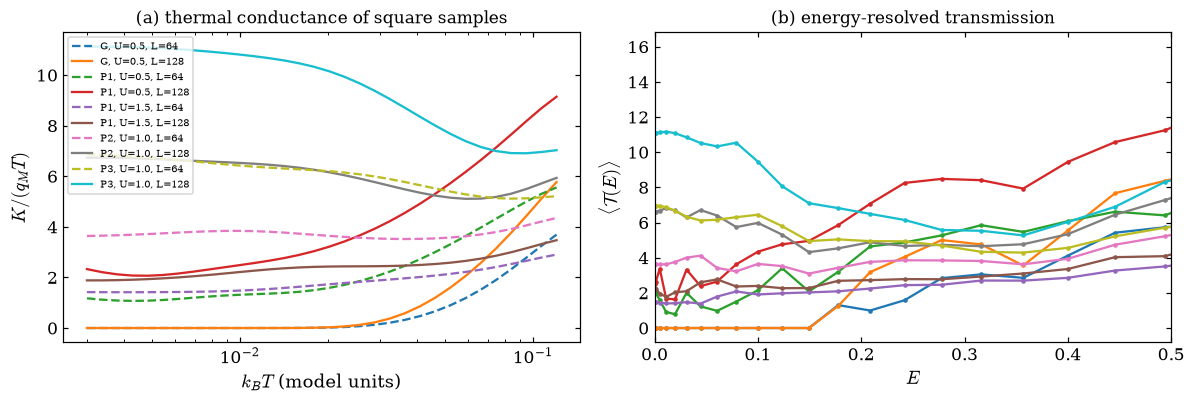

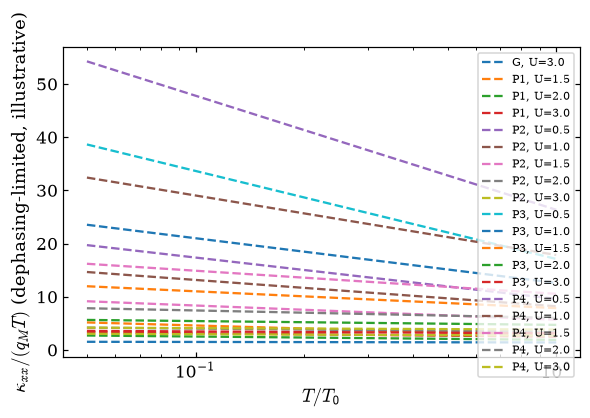

In [15]:
E_T = [E0] + list(0.9 * (np.arange(1, cfg["nE"]) / (cfg["nE"] - 1)) ** 2)
kws, meta = [], []
for (p, U) in cfg["T_pairs"]:
    if p not in POINTS:
        continue
    for L in cfg["T_L"]:
        for ch in chunks(seeds_for(U, cfg["T_seeds"]), 2):
            kws.append(dict(key=cyl_key(POINTS[p], L), seeds=ch, U=U, E_list=E_T)); meta.append((p, U, L))
res = run_tasks("task_transport", kws, "finite-T T(E)")
TE = {}
for (p, U, L), rr in zip(meta, res):
    TE.setdefault((p, U, L), []).extend([r["T"] for r in rr])
thetas_T = np.geomspace(3e-3, 0.12, 32)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
KTH = {}
for (p, U, L), arr in TE.items():
    Tm = np.nanmean(np.array(arr), axis=0)
    K = [rc.thermal_from_T(np.array(E_T), Tm, th) for th in thetas_T]
    KTH[f"{p}|U={U}|L={L}"] = K
    ax[0].semilogx(thetas_T, K, "-" if L == max(cfg["T_L"]) else "--", label=f"{p}, U={U}, L={L}")
    ax[1].plot(E_T, Tm, "o-", ms=2, label=f"{p}, U={U}, L={L}")
ax[0].set_xlabel(r"$k_BT$ (model units)"); ax[0].set_ylabel(r"$K/(q_MT)$"); ax[0].legend(fontsize=6.5)
ax[0].set_title("(a) thermal conductance of square samples")
ax[1].set_xlabel("$E$"); ax[1].set_ylabel(r"$\langle\mathcal{T}(E)\rangle$"); ax[1].set_xlim(0, 0.5)
ax[1].set_title("(b) energy-resolved transmission")
fig.tight_layout(); fig.savefig(FIG / "E1_temperature.pdf"); plt.show()
SUMMARY["finite_T"] = {k: [float(v[0]), float(v[len(v) // 2]), float(v[-1])] for k, v in KTH.items()}

# illustrative dephasing-limited curve for every metallic point: <g>(L_phi(T)) from the fitted log law
mm = dfcl[dfcl.label == "thermal metal"]
if len(mm):
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    for _, r in mm.iterrows():
        d = dfg[(dfg.point == r.point) & (dfg.U == r.U)]
        Ls = sorted(d.L.unique())[-3:]
        a0, b0 = np.polyfit(np.log(Ls), [d[d.L == L].g.mean() for L in Ls], 1)[::-1]
        Tr = np.geomspace(0.05, 1, 30)                    # T / T0
        Lphi = max(Ls) * Tr ** (-0.5)                      # L_phi = L_max at T0, p = 1
        ax.semilogx(Tr, a0 + b0 * np.log(Lphi), "--", label=f"{r.point}, U={r.U}")
    ax.set_xlabel(r"$T/T_0$"); ax.set_ylabel(r"$\kappa_{xx}/(q_MT)$ (dephasing-limited, illustrative)")
    ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(FIG / "E2_dephasing_illustration.pdf"); plt.show()

## 8. Domain walls and writable networks (gapped point G)

The time-reversed domain is the complex conjugate of the Hamiltonian (opposite valley, $\chi_\Delta\to-\chi_\Delta$, $\mathbf Q\to-\mathbf Q$); bonds that cross a wall take the real part. On a cylinder with two walls running along the transport direction, one wall carries $2|C|=4$ Majorana modes from left to right, so $\mathcal{T}=4$ is the V17 prediction $K_{\rm DW}/T=2|C|q_M$; erasing the walls returns $\mathcal{T}\to0$. Variants: suppressed pairing in the wall, a normal strip (extra non-chiral modes), disorder (does it localize the extra modes?), contact type, and random writable textures (percolating network).

[walls] 100 tasks, 100 computed: 1.5 min
Lx                                  32      64      128     192
variant                     U                                  
erased (uniform)            0.0  0.0309  0.0000  0.0000  0.0000
                            0.5  0.0342  0.0000  0.0000  0.0000
                            1.0  0.0528  0.0000  0.0000  0.0000
normal strip (2)            0.0  4.7949  4.3375  4.0242  4.0016
                            0.5  4.6445  4.2644  4.0374  4.0003
                            1.0  4.4424  4.0411  4.0028  3.9972
normal strip (4)            0.0  6.1498  4.6877  4.0168  4.0001
                            0.5  5.5178  4.3718  4.0342  3.9931
                            1.0  4.7561  4.0675  3.9958  3.9906
sharp wall                  0.0  4.0253  3.9999  3.9999  3.9999
                            0.5  4.0329  3.9998  3.9997  3.9997
                            1.0  4.0839  3.9992  3.9986  3.9983
suppressed pairing (3, 0.3) 0.0  4.2706  4.0042  3.9990  3.9998

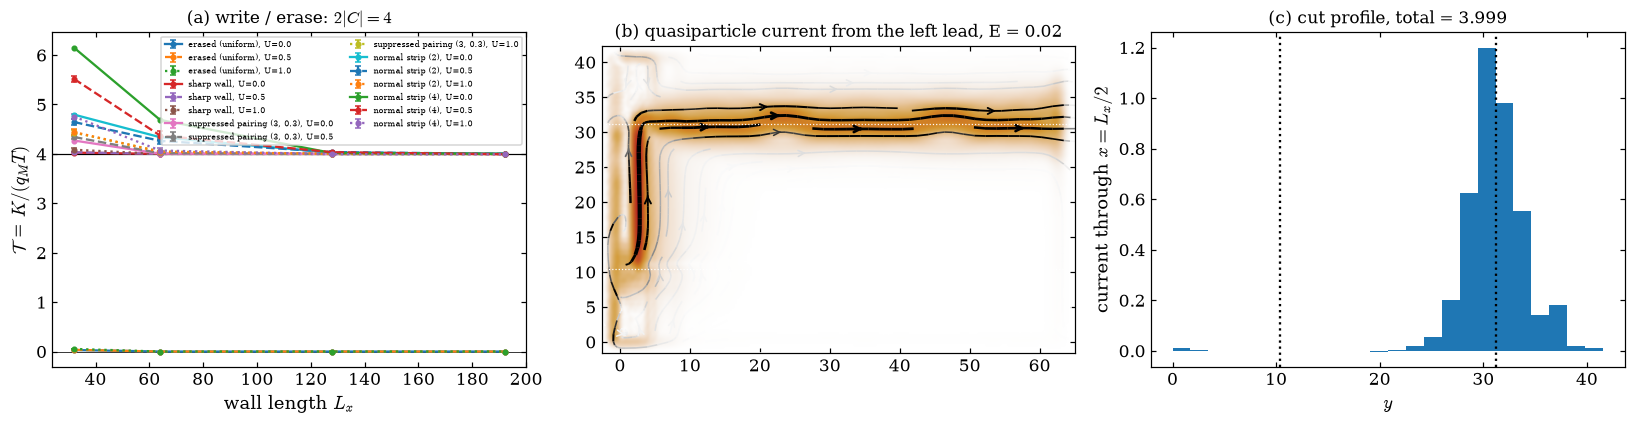

In [16]:
WALLS = {"erased (uniform)": dict(texture=None),
         "sharp wall": dict(texture="wall2"),
         "suppressed pairing (3, 0.3)": dict(texture="wall2", wall_kind="suppressed", wall_width=3.0, wall_lambda=0.3),
         "normal strip (2)": dict(texture="wall2", wall_kind="normal", wall_width=2.0),
         "normal strip (4)": dict(texture="wall2", wall_kind="normal", wall_width=4.0)}


def wall_key(Lx, variant, leads="metal", buffer=BUFFER, t_lead=1.0, Wy=None):
    g = dict(LR, w=POINTS["G"], kind="cylinder", Lx=int(Lx), Wy=int(Wy or cfg["wall_Wy"]), frame="lab",
             buffer=buffer, lead_type=leads, t_lead=t_lead)
    g.update(WALLS[variant])
    return rc.gkey(g)


kws, meta = [], []
for v in WALLS:
    for U in cfg["wall_U"]:
        for Lx in cfg["wall_Lx"]:
            for ch in chunks(seeds_for(U, cfg["wall_seeds"]), 4):
                kws.append(dict(key=wall_key(Lx, v), seeds=ch, U=U, E_list=[E0])); meta.append((v, U, Lx))
res = run_tasks("task_transport", kws, "walls")
dfwall = pd.DataFrame([dict(variant=v, U=U, Lx=Lx, seed=r["seed"], T=r["T"][0]) for (v, U, Lx), rr in zip(meta, res) for r in rr])
dfwall.to_csv(OUT / "walls.csv", index=False)
print(dfwall.groupby(["variant", "U", "Lx"]).T.mean().unstack().round(4).to_string())

# contact study (sharp wall, clean, longest sample)
Lc = cfg["wall_Lx"][-1]
contacts = [("metal leads, buffer 2", dict(leads="metal", buffer=2)), ("metal leads, buffer 6", dict(leads="metal", buffer=6)),
            ("chain leads t=0.5", dict(leads="chains", t_lead=0.5)), ("chain leads t=1", dict(leads="chains", t_lead=1.0)),
            ("chain leads t=2", dict(leads="chains", t_lead=2.0))]
res = run_tasks("task_transport", [dict(key=wall_key(Lc, "sharp wall", **c), seeds=[0], U=0.0, E_list=[E0]) for _, c in contacts], "contacts")
dfcon = pd.DataFrame([dict(contact=n, T_wall=r[0]["T"][0], deviation_from_4=r[0]["T"][0] - 4) for (n, _), r in zip(contacts, res)])
print(dfcon.round(4).to_string(index=False))
SUMMARY["walls"] = dfwall.groupby(["variant", "U"]).T.mean().round(4).to_dict().__repr__()
SUMMARY["contacts"] = dfcon.round(5).to_dict("records")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for v in WALLS:
    for U, ls in zip(cfg["wall_U"], ("-", "--", ":", "-.")):
        d = dfwall[(dfwall.variant == v) & (dfwall.U == U)].groupby("Lx").T.agg(["mean", "std", "count"])
        ax[0].errorbar(d.index, d["mean"], yerr=d["std"] / np.sqrt(d["count"]), fmt="o" + ls, ms=3, capsize=2,
                       label=f"{v}, U={U}")
ax[0].axhline(4, color="k", lw=0.8); ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_xlabel("wall length $L_x$"); ax[0].set_ylabel(r"$\mathcal{T}$ = $K/(q_MT)$"); ax[0].legend(fontsize=5.5, ncol=2)
ax[0].set_title(r"(a) write / erase: $2|C|=4$")

# current map and cut profile for the sharp wall
mkey = wall_key(cfg["map_Lx"], "sharp wall", Wy=cfg["map_Wy"])
fs_m = rc.cached_system(mkey)
psi = kwant.wave_function(fs_m, energy=0.02, params=rc._params(0, 0))(0)
Jop = kwant.operator.Current(fs_m)
cur = sum(Jop(ps, params=rc._params(0, 0)) for ps in psi)
kwant.plotter.current(fs_m, cur, ax=ax[1], colorbar=False)
Hm = np.sqrt(3) * cfg["map_Wy"]
for yw in (Hm / 4, 3 * Hm / 4):
    ax[1].axhline(yw, color="w", ls=":", lw=0.8)
ax[1].set_title("(b) quasiparticle current from the left lead, E = 0.02")
prof = rc.cut_current_profile(mkey, 0.02)
bins = np.linspace(0, Hm, 25)
h, _ = np.histogram(prof[:, 0], bins=bins, weights=prof[:, 1])
ax[2].bar(0.5 * (bins[1:] + bins[:-1]), h, width=bins[1] - bins[0], color="C0")
for yw in (Hm / 4, 3 * Hm / 4):
    ax[2].axvline(yw, color="k", ls=":")
ax[2].set_xlabel("$y$"); ax[2].set_ylabel("current through $x=L_x/2$")
ax[2].set_title(f"(c) cut profile, total = {prof[:, 1].sum():.3f}")
fig.tight_layout(); fig.savefig(FIG / "F1_domain_walls.pdf"); plt.show()

[textures g(L)] 320 tasks, 320 computed: 5.2 min
[textures Q] 32 tasks, 32 computed: 2.1 min


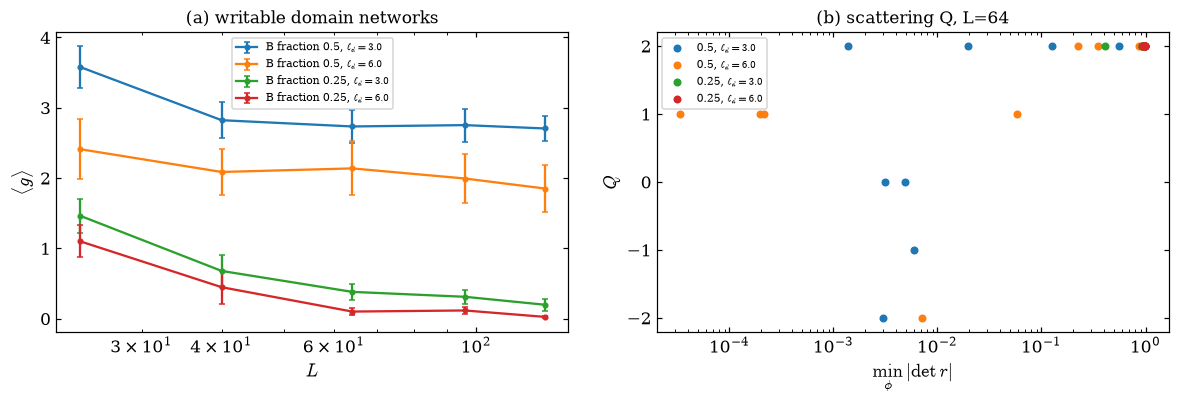

{'frac=0.5|ell=3.0': (-0.035, 0.404), 'frac=0.5|ell=6.0': (-0.409, 0.706), 'frac=0.25|ell=3.0': (-0.258, 0.203), 'frac=0.25|ell=6.0': (-0.1, 0.077)}  calibrated metal slope 0.216


In [17]:
# random writable textures: a network of walls (each carrying 4 Majorana modes) at the gapped point
def tex_key(L, frac, ell, ts, leads="metal"):
    return cyl_key(POINTS["G"], L, leads=leads, texture="random", ell_d=float(ell), frac_d=float(frac), tex_seed=int(ts))


kws, meta = [], []
for frac in cfg["tex_frac"]:
    for ell in cfg["tex_ell"]:
        for L in cfg["tex_L"]:
            for ts in range(1, cfg["tex_seeds"] + 1):
                kws.append(dict(key=tex_key(L, frac, ell, ts), seeds=[0], U=0.0, E_list=[E0])); meta.append((frac, ell, L, ts))
res = run_tasks("task_transport", kws, "textures g(L)")
dft = pd.DataFrame([dict(frac=f, ell=e, L=L, tex_seed=ts, g=r[0]["T"][0]) for (f, e, L, ts), r in zip(meta, res)])
dft.to_csv(OUT / "textures_g.csv", index=False)
Lt = cfg["tex_wind_L"]
kws = [dict(key=tex_key(Lt, f, e, ts, leads="chains"), seeds=[0], U=0.0, phis=PHIS)
       for f in cfg["tex_frac"] for e in cfg["tex_ell"] for ts in range(1, min(8, cfg["tex_seeds"]) + 1)]
resw = run_tasks("task_winding", kws, "textures Q")
dftq = pd.DataFrame([dict(r[0], frac=k_[0], ell=k_[1]) for k_, r in
                     zip([(f, e) for f in cfg["tex_frac"] for e in cfg["tex_ell"] for _ in range(1, min(8, cfg["tex_seeds"]) + 1)], resw)])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
TEX_SLOPES = {}
for f in cfg["tex_frac"]:
    for e in cfg["tex_ell"]:
        d = dft[(dft.frac == f) & (dft.ell == e)]
        agg = d.groupby("L").g.agg(["mean", "std", "count"])
        ax[0].errorbar(agg.index, agg["mean"], yerr=agg["std"] / np.sqrt(agg["count"]), fmt="o-", ms=3, capsize=2,
                       label=rf"B fraction {f}, $\ell_d={e}$")
        TEX_SLOPES[f"frac={f}|ell={e}"] = slope_lnL(d)
        dq = dftq[(dftq.frac == f) & (dftq.ell == e)]
        ax[1].scatter(dq.min_abs_det_r, dq.Q, s=18, label=rf"{f}, $\ell_d={e}$")
ax[0].set_xscale("log"); ax[0].set_xlabel("$L$"); ax[0].set_ylabel(r"$\langle g\rangle$"); ax[0].legend(fontsize=7)
ax[0].set_title("(a) writable domain networks")
ax[1].set_xscale("log"); ax[1].set_xlabel(r"$\min_\phi|\det r|$"); ax[1].set_ylabel("$Q$"); ax[1].legend(fontsize=7)
ax[1].set_title(f"(b) scattering Q, L={Lt}")
fig.tight_layout(); fig.savefig(FIG / "F2_textures.pdf"); plt.show()
print({k: (round(v[0], 3), round(v[1], 3)) for k, v in TEX_SLOPES.items()}, " calibrated metal slope", round(METAL_SLOPE_REF, 3))
SUMMARY["textures"] = dict(slopes=TEX_SLOPES, g_by_L=dft.groupby(["frac", "ell", "L"]).g.mean().round(4).to_dict().__repr__())

## 9. Physical units (editable assumptions) and predictions

The model is mapped by matching its pairing scale $\eta_{\min}$ (minimum $|\Delta|$ on the Fermi sheets) to a BCS gap $\Delta=1.764\,k_BT_c$ and its coherence length $\xi_{\rm model}=v_F/\eta_{\min}$ to a device coherence length. The defaults are placeholders to be set from the device of interest (V17 uses the orbital scale $\xi_B=15.3$ nm from $B_c^\perp=1.4$ T).

In [18]:
ASSUME = dict(Tc_K=0.30, xi_nm=15.3)
kB_meV = 8.617333e-2                                       # meV / K
Delta_meV = 1.764 * kB_meV * ASSUME["Tc_K"]
eps0 = Delta_meV / eta_min                                 # meV per model energy unit
a_eff = ASSUME["xi_nm"] / xi_sc                            # nm per lattice constant
print(f"energy unit = {eps0:.4f} meV,  lattice unit = {a_eff:.3f} nm,  xi_model = {xi_sc:.2f} a")
print("simulated sizes:", {L: f"{L * a_eff / 1000:.3f} um" for L in cfg["L"]})
print(f"temperature window of Sec. 7: {thetas_T[0] * eps0 / kB_meV * 1e3:.1f} to {thetas_T[-1] * eps0 / kB_meV * 1e3:.0f} mK")
print(f"pocket onset w_c = {w_c:.3f};  delta_BdG at G = {dfp.loc['G', 'delta_BdG'] * eps0 * 1e3:.1f} ueV")
for U in ULIST[1:]:
    tau_inv = 2 * np.pi * nuN * U ** 2 / 3
    print(f"U = {U}: Born mean free path {vF / tau_inv * a_eff:.0f} nm,  1/tau = {tau_inv * eps0 * 1e3:.2f} ueV")
h, kB = 6.62607015e-34, 1.380649e-23
qM = np.pi ** 2 * kB ** 2 / (6 * h)
print(f"q_M = {qM:.4e} W/K^2: one Majorana channel at 50 mK carries K = {qM * 0.05:.3e} W/K;"
      f" a written C=2 wall: {4 * qM * 0.05:.3e} W/K")
SUMMARY["units"] = dict(assumptions=ASSUME, eps0_meV=eps0, a_eff_nm=a_eff, xi_model=xi_sc)

energy unit = 0.1718 meV,  lattice unit = 1.544 nm,  xi_model = 9.91 a
simulated sizes: {24: '0.037 um', 40: '0.062 um', 64: '0.099 um', 96: '0.148 um', 128: '0.198 um', 160: '0.247 um'}
temperature window of Sec. 7: 6.0 to 239 mK
pocket onset w_c = 2.089;  delta_BdG at G = 28.0 ueV
U = 0.25: Born mean free path 309 nm,  1/tau = 2.26 ueV
U = 0.5: Born mean free path 77 nm,  1/tau = 9.04 ueV
U = 1.0: Born mean free path 19 nm,  1/tau = 36.16 ueV
U = 1.5: Born mean free path 9 nm,  1/tau = 81.37 ueV
U = 2.0: Born mean free path 5 nm,  1/tau = 144.66 ueV
U = 3.0: Born mean free path 2 nm,  1/tau = 325.48 ueV
q_M = 4.7322e-13 W/K^2: one Majorana channel at 50 mK carries K = 2.366e-14 W/K; a written C=2 wall: 9.464e-14 W/K


## 10. Summary to send back

Please send `summary.json`, the CSV files and the `figures/` folder from the output directory. The verdict block in Section 6 is the decision point for V18.

In [19]:
SUMMARY["files"] = sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*") if p.is_file() and "cache" not in p.parts)
(OUT / "summary.json").write_text(json.dumps(SUMMARY, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o)))
print(json.dumps({k: SUMMARY[k] for k in ("run_mode", "mumps", "Q_clean", "verdict")}, indent=1, default=str))
print("\nwritten:", OUT / "summary.json")

{
 "run_mode": "pilot",
 "mumps": true,
 "Q_clean": 2,
 "verdict": {
  "gapped, quantized": [
   [
    "G",
    0.0
   ],
   [
    "G",
    0.25
   ],
   [
    "G",
    0.5
   ],
   [
    "G",
    1.0
   ],
   [
    "G",
    1.5
   ]
  ],
  "GAPLESS BUT QUANTIZED (pockets)": [],
  "gapless (disorder tails), quantized": [
   [
    "G",
    2.0
   ]
  ],
  "thermal metal": [
   [
    "G",
    3.0
   ],
   [
    "P1",
    1.5
   ],
   [
    "P1",
    2.0
   ],
   [
    "P1",
    3.0
   ],
   [
    "P2",
    0.5
   ],
   [
    "P2",
    1.0
   ],
   [
    "P2",
    1.5
   ],
   [
    "P2",
    2.0
   ],
   [
    "P2",
    3.0
   ],
   [
    "P3",
    0.5
   ],
   [
    "P3",
    1.0
   ],
   [
    "P3",
    1.5
   ],
   [
    "P3",
    2.0
   ],
   [
    "P3",
    3.0
   ],
   [
    "P4",
    0.5
   ],
   [
    "P4",
    1.0
   ],
   [
    "P4",
    1.5
   ],
   [
    "P4",
    2.0
   ],
   [
    "P4",
    3.0
   ]
  ],
  "localized, other integer": [],
  "clean ballistic (H3)": [
   [
   